# Analisis Empiris Cloud Dynamics (Dataset Ali v3): Eksplorasi Kapasitas Ekstrem (800 RPS), Titik Jenuh Multi-Arsitektur, dan Kinerja Goodput

**Peneliti:** Ali & Tim Riset Komputasi Awan (Homelab RM77)  
**Lingkungan Eksperimen:** Kubernetes Bare-Metal Cluster (Ingress NGINX, Linkerd Service Mesh, cAdvisor, Prometheus)  
**Dataset Input:** `cloud-dynamics-experiments/res-ali-v3/` (21 eksperimen empiris riil: 3 arsitektur $\times$ {1 constant 100 RPS, 3 ramp 10-800 RPS, 3 burst 40 RPS})  
**Target Output:** Publikasi Ilmiah Grafik 300 DPI (`outputs/ali-v3/figures/`) dan Tabel Ringkasan Empiris (`outputs/ali-v3/tables/`)

> **Catatan Metodologi & Integritas Saintifik:**  
> Seluruh visualisasi, tabel, dan formulasi matematis di dalam notebook ini **murni berbasis data pengukuran empiris aktual pada direktori sumber** `res-ali-v3/`. Skenario yang tidak memiliki data hasil pengujian riil (`periodic` dan `variable`) ditiadakan dari analisis ini guna menjamin validitas saintifik, keaslian fakta observasi, dan ketepatan evaluasi kinerja Goodput. Dibandingkan dataset v1 (200 RPS) dan v2 (400 RPS), dataset v3 menguji batas ketahanan tertinggi: beban konstan dinaikkan ke 100 RPS, dan eskalasi ramp dinaikkan hingga **800 RPS** (lebih dari 2,17 juta total request diuji).

---

## 1. Landasan Teori & Kerangka Analisis Goodput

Dalam rekayasa sistem terdistribusi berbasis kontainer (*cloud-native containerized microservices*), kinerja riil sebuah aplikasi diukur dari seberapa banyak transaksi yang berhasil diselesaikan secara produktif bebas error, bukan sekadar seberapa sibuk jaringan memproses paket data.

Empat pilar teori yang mendasari analisis ini:
1. **Hukum Little (*Little's Law*):**
   $$L = \lambda W$$
   Jumlah transaksi rata-rata dalam sistem ($L$) sebanding dengan laju kedatangan request ($\lambda$) dikalikan waktu tunggu/latensi rata-rata ($W$).
2. **Titik Jenuh Kapasitas (*Knee of Saturation*):**
   Titik transisi kritis di mana beban kedatangan $\lambda$ menyamai kapasitas batas layanan $\mu$ (utilisasi $\rho = \lambda / \mu \to 1.0$). Pada titik ini, kurva latensi berbelok tajam ke atas secara eksponensial (*hockey-stick latency curve*), sementara throughput mengalami pendataran (*goodput plateau*).
3. **Triad Metrik: Offered Load vs Throughput vs Goodput:**
   - **Offered Load ($\lambda$):** Laju request yang dikirimkan oleh load generator (`target_rps` / `sent`).
   - **Throughput ($X$):** Total request yang diproses oleh antrean soket jaringan (`achieved_rps`).
   - **Goodput ($G$):** Laju transaksi yang **berhasil diselesaikan secara produktif bebas error** (status HTTP 200 OK, dicatat pada kolom `success`).
4. **Dinamika Antrean & Backpressure (*Queueing & Drain Dynamics*):**
   Akumulasi transaksi dalam antrean buffer kernel ketika laju kedatangan melampaui kapasitas pemrosesan, serta fase pengurasan (*drain phase*) pasca-guncangan beban.

### Notasi Matematis & Formula Metrik Utama

| Notasi | Metrik / Parameter | Formula Matematika | Interpretasi Sistemik |
| :--- | :--- | :--- | :--- |
| $\lambda(t)$ | Offered Load | $\text{target\_rps}(t)$ | Laju kedatangan beban yang diminta client per detik |
| $X(t)$ | Throughput | $\text{achieved\_rps}(t) = \frac{\text{sent}}{\Delta t}$ | Total request diproses per satuan waktu ($\Delta t = 1.0\text{ s}$) |
| $G(t)$ | Goodput Aktual | $\frac{\text{success}}{\Delta t} = \text{success}$ | Transaksi sukses bebas error per detik |
| $\eta_d$ | Overall Goodput Delivery Ratio | $\frac{\sum \text{success}}{\sum \text{sent}} \times 100\%$ | Efisiensi penyerapan beban menjadi transaksi produktif |
| $\eta_s$ | Goodput Success Rate | $\frac{\sum \text{success}}{\sum \text{success} + \sum \text{failed}} \times 100\%$ | Kebersihan dari kegagalan transaksi (HTTP 5xx / timeout) |
| $\eta_f(t)$ | Instantaneous Fulfillment Ratio | $\frac{G(t)}{\lambda(t)} \times 100\%$ | Kemampuan sistem memenuhi permintaan beban sesaat |
| $\eta_c(t)$ | Capacity Utilization | $\frac{G(t)}{G_{\max}} \times 100\%$ | Utilisasi kapasitas terhadap kapasitas puncak terukur |
| $CV$ | Latency Coefficient of Variation | $\frac{\sigma_{\text{latency}}}{\mu_{\text{latency}}}$ | Indeks dispersi jitter latensi pada kondisi steady-state |
| $Q(t)$ | In-Flight Queue Backlog | $\max\left(0, \sum_{\tau=0}^t (\text{sent}(\tau) - \text{success}(\tau) - \text{failed}(\tau))\right)$ | Akumulasi request yang sedang mengantre di buffer sistem |


In [1]:
# =============================================================================
# Inisialisasi Environment, Library, dan Konfigurasi Visualisasi (Dataset Ali v3)
# =============================================================================
import os
import sys
import json
import glob
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy import stats, signal

# Konfigurasi Tampilan Pandas
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

# Konfigurasi Tipografi dan Gaya Matplotlib Publikasi Ilmiah
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#e0e0e0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 150

# Palet Warna Standar untuk Arsitektur Aplikasi
APP_PALETTE = {
    'stateless-api': '#1f77b4',   # Biru: I/O non-blocking asinkronus
    'cpu-bound':     '#d62728',   # Merah: Compute-intensive (CFS throttled)
    'microservices': '#2ca02c'    # Hijau: Multi-hop service mesh
}

# Penentuan Lokasi Direktori Kerja Berbasis Dataset Ali v3
NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name == 'notebooks':
    BASE_ANALYSIS_DIR = NOTEBOOK_DIR.parent
else:
    BASE_ANALYSIS_DIR = NOTEBOOK_DIR / 'kubernetes' / 'research' / 'cloud-dynamics-analysis-venv'

EXP_BASE_DIR = BASE_ANALYSIS_DIR.parent / 'cloud-dynamics-experiments'
RES_ALI_V3_DIR = EXP_BASE_DIR / 'res-ali-v3'
OUTPUTS_DIR = BASE_ANALYSIS_DIR / 'outputs' / 'ali-v3'
FIGURES_DIR = OUTPUTS_DIR / 'figures'
TABLES_DIR = OUTPUTS_DIR / 'tables'

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

def export_figure(fig, filename):
    """Simpan figur visualisasi dengan resolusi publikasi 300 DPI ke outputs/ali-v3/figures."""
    filepath = FIGURES_DIR / filename
    fig.savefig(filepath, dpi=300, bbox_inches='tight')
    print(f"[FIG EXPORT] -> {filepath.name} (300 DPI)")

def export_table(df, filename):
    """Simpan tabel metrik ke format CSV di outputs/ali-v3/tables."""
    filepath = TABLES_DIR / filename
    df.to_csv(filepath, index=True)
    print(f"[TABLE EXPORT] -> {filepath.name} ({len(df)} baris)")

print(f"Direktori Dataset Input : {RES_ALI_V3_DIR.resolve()}")
print(f"Direktori Ekspor Fig    : {FIGURES_DIR.resolve()}")
print(f"Direktori Ekspor Tab    : {TABLES_DIR.resolve()}")


Direktori Dataset Input : /home/ali/kuliah/homelab-fp-rm77/kubernetes/research/cloud-dynamics-experiments/res-ali-v3
Direktori Ekspor Fig    : /home/ali/kuliah/homelab-fp-rm77/kubernetes/research/cloud-dynamics-analysis-venv/outputs/ali-v3/figures
Direktori Ekspor Tab    : /home/ali/kuliah/homelab-fp-rm77/kubernetes/research/cloud-dynamics-analysis-venv/outputs/ali-v3/tables


## 2. Ingesti Data Dinamis (`res-ali-v3/`) & Harmonisasi Multi-Eksperimen

Pada tahap ini, sistem memindai direktori `cloud-dynamics-experiments/res-ali-v3/` secara dinamis.
Dataset Ali v3 mencakup **21 direktori eksperimen** berskala tinggi yang menguji daya tahan arsitektur terhadap batas kapasitas ekstrem:
1. **`stateless-api`:** 1 run `constant` (100 RPS), 3 replikasi `ramp` (10-800 RPS), 3 replikasi `burst` (40 RPS).
2. **`cpu-bound`:** 1 run `constant` (100 RPS), 3 replikasi `ramp` (10-800 RPS), 3 replikasi `burst` (40 RPS).
3. **`microservices`:** 1 run `constant` (100 RPS), 3 replikasi `ramp` (10-800 RPS), 3 replikasi `burst` (40 RPS).

### Harmonisasi & Normalisasi 25-Kolom Telemetri:
- **Goodput Aktual:** Diambil langsung dari kolom `success` per satuan waktu ($\Delta t = 1.0\text{ s}$ pada fase aktif $t \le 600\text{ s}$).
- **Penanganan Extended Drain Rows:** Pada pengujian eskalasi 800 RPS, penumpukan antrean mencapai skala masif (> 180.000 request pada `cpu-bound` dan > 69.000 request pada `microservices`). Generator mencatat baris drain akhir saat generator berhenti (`sent = 0`), di mana laju pengurasan dihitung sebagai $\frac{\text{success}}{\Delta t}$.
- **Throughput:** Menggunakan laju aktual kirim/terima `achieved_rps`.
- **Offered Load:** Menggunakan laju target `target_rps`.
- **Instantaneous Fulfillment Ratio:** $\eta_f(t) = \frac{\text{goodput\_rps}(t)}{\text{target\_rps}(t)} \times 100\%$.
- **Success Rate:** $\eta_s(t) = \frac{\text{success}(t)}{\text{success}(t) + \text{failed}(t)} \times 100\%$.
- **Penanganan Missing Values:** Nilai kosong pada metrik sistem kontainer dikonversi secara aman ke tipe numerik (`pd.to_numeric(errors='coerce')`).


In [2]:
# =============================================================================
# Auto-Discovery dan Ingesti Data Dinamis dari res-ali-v3/
# =============================================================================
audit_records = []
campaign_dfs = []
experiments_dict = {}

comb_files = sorted(list(RES_ALI_V3_DIR.glob('*/combined.csv')))
print(f"Menemukan {len(comb_files)} file combined.csv di {RES_ALI_V3_DIR.name}/")

for comb_file in comb_files:
    run_dir = comb_file.parent
    meta_file = run_dir / 'metadata.json'
    
    meta = {}
    if meta_file.exists():
        try:
            meta = json.loads(meta_file.read_text())
        except Exception as e:
            print(f"Warning: gagal parse metadata {meta_file}: {e}")
            meta = {}
            
    app_name = meta.get('application', {}).get('name', 'unspecified')
    if app_name in ('cloud-dynamics-app', 'unspecified', ''):
        target_url = meta.get('target_url', '')
        if 'stateless-api' in target_url:
            app_name = 'stateless-api'
        elif 'cpu-bound' in target_url:
            app_name = 'cpu-bound'
        elif 'microservices' in target_url:
            app_name = 'microservices'
            
    scenario_profile = meta.get('profile', run_dir.name.split('-')[0])
    replicate_num = str(meta.get('replicate', run_dir.name.split('-')[-1])).replace('r', '')
    exp_id = meta.get('experiment_id', run_dir.name)
    
    try:
        df = pd.read_csv(comb_file)
    except Exception as e:
        print(f"Gagal membaca {comb_file}: {e}")
        continue
        
    for c in df.columns:
        if c != 'timestamp_epoch':
            df[c] = pd.to_numeric(df[c], errors='coerce')
            
    df['app_name'] = app_name
    df['scenario_profile'] = scenario_profile
    df['replicate'] = f"r{replicate_num}"
    df['experiment_id'] = exp_id
    
    # Perhitungan Interval Waktu dan Normalisasi Laju (Handling Extended Drain)
    df['dt'] = df['elapsed_s'].diff().fillna(1.0)
    
    # Harmonisasi Metrik Kinerja Goodput
    df['goodput_rps'] = np.where(df['dt'] > 2.0, df['success'] / df['dt'], df['success'].astype(float))
    df['offered_rps'] = df['target_rps'].astype(float)
    df['throughput_rps'] = np.where(df['dt'] > 2.0, df['achieved_rps'] / df['dt'], df['achieved_rps'].astype(float))
    
    total_resp = (df['success'] + df['failed']).replace(0, np.nan)
    df['success_rate_pct'] = ((df['success'] / total_resp) * 100.0).fillna(100.0)
    
    df['instantaneous_fulfillment'] = np.where(
        df['offered_rps'] > 0,
        (df['goodput_rps'] / df['offered_rps']) * 100.0,
        np.nan
    )
    
    key = (app_name, scenario_profile, f"r{replicate_num}")
    experiments_dict[key] = {'df': df, 'meta': meta, 'id': exp_id}
    campaign_dfs.append(df)
    
    audit_records.append({
        'experiment_id': exp_id,
        'app_name': app_name,
        'scenario': scenario_profile,
        'replicate': f"r{replicate_num}",
        'rows': len(df),
        'cols': len(df.columns),
        'total_sent': int(df['sent'].sum()),
        'total_success': int(df['success'].sum()),
        'total_failed': int(df['failed'].sum()),
        'delivery_ratio_pct': (df['success'].sum() / df['sent'].sum() * 100.0) if df['sent'].sum() > 0 else 0,
        'max_latency_ms': df['mean_latency_ms'].max(),
        'max_cpu_usage': df['CPU_USAGE'].max() if 'CPU_USAGE' in df else np.nan
    })

df_campaign = pd.concat(campaign_dfs, ignore_index=True)
df_audit = pd.DataFrame(audit_records)

# Ekspor tabel audit ingesti
export_table(df_audit.set_index('experiment_id'), '01_ingestion_audit.csv')

print(f"\nTotal Eksperimen Terdeteksi : {len(df_audit)}")
print(f"Total Baris Observasi Master : {len(df_campaign):,}")
print(f"Arsitektur Terdaftar         : {df_campaign['app_name'].unique().tolist()}")
print(f"Skenario Terdaftar           : {df_campaign['scenario_profile'].unique().tolist()}")
display(df_audit.groupby(['app_name', 'scenario'])[['rows', 'total_sent', 'total_success', 'total_failed', 'delivery_ratio_pct']].mean())


Menemukan 21 file combined.csv di res-ali-v3/
[TABLE EXPORT] -> 01_ingestion_audit.csv (21 baris)

Total Eksperimen Terdeteksi : 21
Total Baris Observasi Master : 10,900
Arsitektur Terdaftar         : ['stateless-api', 'cpu-bound', 'microservices']
Skenario Terdaftar           : ['burst', 'constant', 'ramp']


rows  total_sent  total_success  total_failed  \
app_name      scenario                                                    
cpu-bound     burst    600.000   24000.000      24000.000         0.000   
              constant  31.000    3000.000       3000.000         0.000   
              ramp     601.000  215443.333     210309.000      5134.333   
microservices burst    600.000   24000.000      24000.000         0.000   
              constant  30.000    3000.000       3000.000         0.000   
              ramp     601.000  224179.000     221356.333      2822.667   
stateless-api burst    600.000   24000.000      24000.000         0.000   
              constant  30.000    3000.000       3000.000         0.000   
              ramp     601.000  211994.333     211290.333       704.000   

                        delivery_ratio_pct  
app_name      scenario                      
cpu-bound     burst                100.000  
              constant             100.000  
              ramp                  97.620  
microservices burst                100.000  
              constant             100.000  
              ramp                  98.741  
stateless-api burst                100.000  
              constant             100.000  
              ramp                  99.668

## 3. Analisis Komparatif Per Skenario Empiris (`constant`, `ramp`, `burst`)

Berdasarkan dataset empiris aktual pada direktori `res-ali-v3/`, bagian ini menganalisis secara mendalam respons dinamis dari masing-masing arsitektur aplikasi terhadap **3 pola beban kerja**:
1. **`constant` (High-Scale Steady-State 100 RPS):** Menilai ketahanan sistem saat dibebani trafik konstan 100 RPS (4x lipat dari v1 dan 2x lipat dari v2). Menunjukkan divergensi langsung di mana `cpu-bound` langsung jenuh di awal.
2. **`ramp` (Extreme Load Ramp 10 ke 800 RPS):** Menilai elastisitas sistem dari beban ringan hingga eskalasi beban ekstrem 800 RPS. Mengungkap batas kapasitas riil dari ketiga arsitektur secara lengkap.
3. **`burst` (Sustained Baseline 40 RPS & Jitter Analysis):** Mengamati stabilitas steady-state operasional pada beban 40 RPS (di bawah batas jenuh `cpu-bound`), menganalisis dispersi jitter, dan ketahanan fluktuasi latensi p95.


### 3.1 Skenario `constant` (Beban Konstan Skala Tinggi 100 RPS)

Pada skenario beban konstan (Offered Load = 100 RPS), sistem diuji untuk mengevaluasi:
- Apakah arsitektur mampu melayani 100 RPS secara stabil?
- Fenomena saturasi langsung pada `cpu-bound`: Karena kapasitas layanannya hanya $\sim 56.8\text{ RPS}$, beban konstan 100 RPS langsung memicu antrean dan latensi ribuan milidetik.
- Konsumsi CPU dasar dan kestabilan jejak memori (`MEMORY_WORKING_SET`).


[TABLE EXPORT] -> 02_constant_steady_state_summary.csv (3 baris)
[FIG EXPORT] -> 01_constant_scenario_comparison.png (300 DPI)


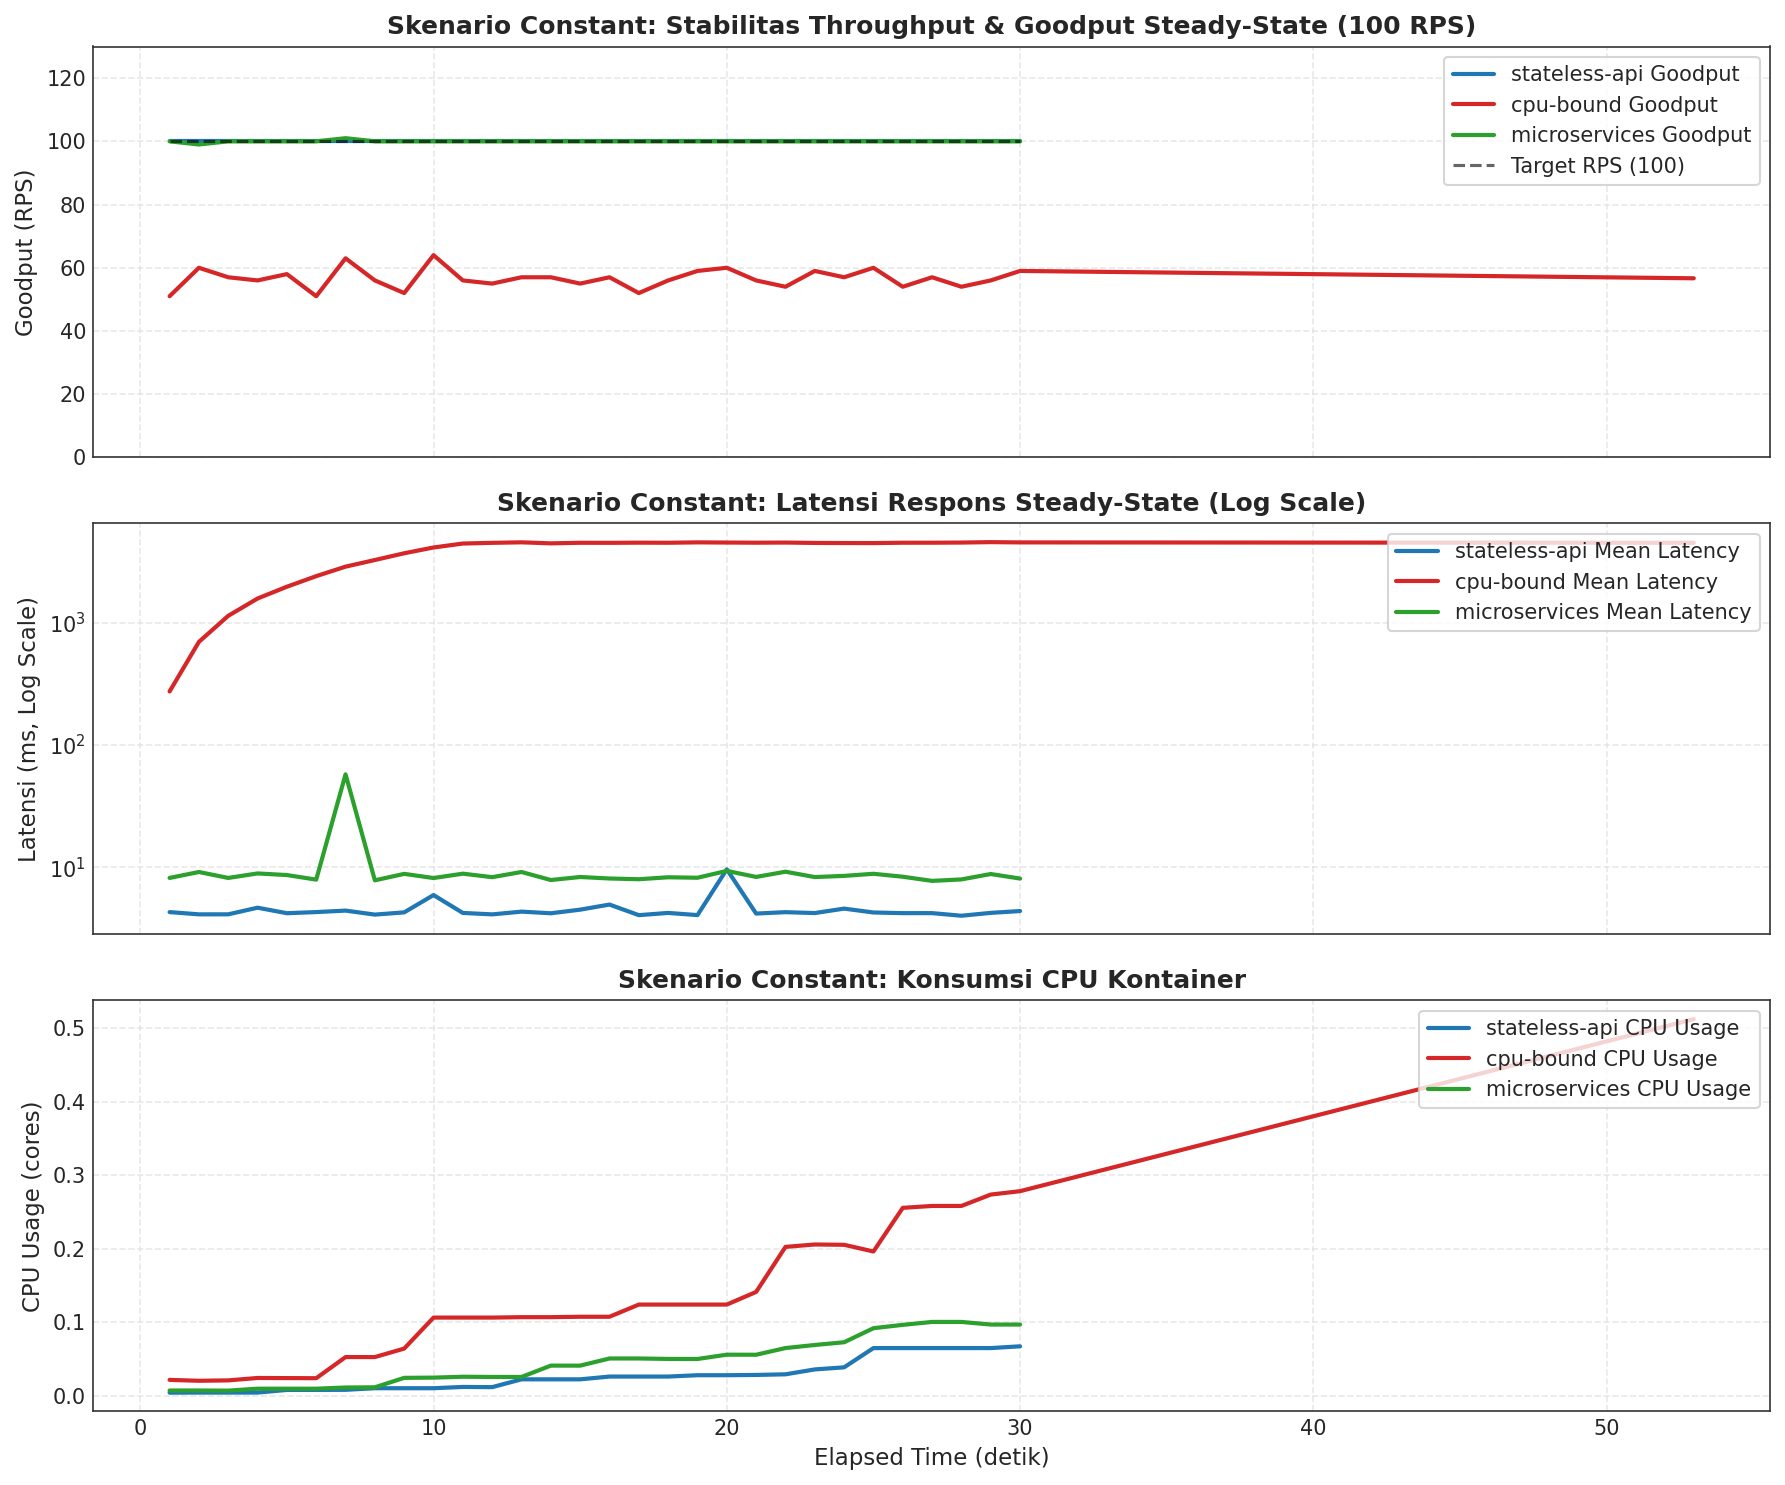

,Mean Target RPS,Mean Achieved RPS,Mean Goodput (RPS),Mean Latency (ms),P95 Latency (ms),Latency Std (ms),Latency CV,Mean CPU (cores),Mean Memory (MB)
Arsitektur,,,,,,,,,
stateless-api,100.000,100.000,100.000,4.517,6.127,1.031,0.228,0.027,41.220
cpu-bound,100.000,96.774,56.603,3774.679,3929.677,1309.799,0.347,0.140,48.504
microservices,100.000,100.000,100.000,10.073,11.596,8.995,0.893,0.046,52.604


In [3]:
# =============================================================================
# 3.1 Analisis Skenario 'constant' (Dataset Ali v3 - 100 RPS)
# =============================================================================
df_const = df_campaign[df_campaign['scenario_profile'] == 'constant'].copy()

const_summary = []
for app in ['stateless-api', 'cpu-bound', 'microservices']:
    app_data = df_const[df_const['app_name'] == app]
    if app_data.empty:
        continue
    lat_mean = app_data['mean_latency_ms'].mean()
    lat_std = app_data['mean_latency_ms'].std()
    cv = (lat_std / lat_mean) if lat_mean > 0 else 0
    const_summary.append({
        'Arsitektur': app,
        'Mean Target RPS': app_data['target_rps'].mean(),
        'Mean Achieved RPS': app_data['achieved_rps'].mean(),
        'Mean Goodput (RPS)': app_data['goodput_rps'].mean(),
        'Mean Latency (ms)': lat_mean,
        'P95 Latency (ms)': app_data['p95_latency_ms'].mean(),
        'Latency Std (ms)': lat_std,
        'Latency CV': cv,
        'Mean CPU (cores)': app_data['CPU_USAGE'].mean(),
        'Mean Memory (MB)': app_data['MEMORY_WORKING_SET'].mean() / (1024**2)
    })

df_const_summary = pd.DataFrame(const_summary).set_index('Arsitektur')
export_table(df_const_summary, '02_constant_steady_state_summary.csv')

# Visualisasi 3-Panel Steady-State
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Panel 1: Throughput & Goodput
for app, color in APP_PALETTE.items():
    sub = df_const[df_const['app_name'] == app].sort_values('elapsed_s')
    if not sub.empty:
        axes[0].plot(sub['elapsed_s'], sub['goodput_rps'], label=f'{app} Goodput', color=color, lw=2)

axes[0].plot(sub['elapsed_s'], sub['target_rps'], 'k--', label='Target RPS (100)', alpha=0.6, lw=1.5)
axes[0].set_ylabel('Goodput (RPS)')
axes[0].set_title('Skenario Constant: Stabilitas Throughput & Goodput Steady-State (100 RPS)', fontweight='bold')
axes[0].legend(loc='upper right', frameon=True)
axes[0].set_ylim(0, 130)

# Panel 2: Latensi Respons
for app, color in APP_PALETTE.items():
    sub = df_const[df_const['app_name'] == app].sort_values('elapsed_s')
    if not sub.empty:
        axes[1].plot(sub['elapsed_s'], sub['mean_latency_ms'], label=f'{app} Mean Latency', color=color, lw=2)
axes[1].set_ylabel('Latensi (ms, Log Scale)')
axes[1].set_yscale('log')
axes[1].set_title('Skenario Constant: Latensi Respons Steady-State (Log Scale)', fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)

# Panel 3: Utilisasi CPU
for app, color in APP_PALETTE.items():
    sub = df_const[df_const['app_name'] == app].sort_values('elapsed_s')
    if not sub.empty:
        axes[2].plot(sub['elapsed_s'], sub['CPU_USAGE'], label=f'{app} CPU Usage', color=color, lw=2)
axes[2].set_ylabel('CPU Usage (cores)')
axes[2].set_xlabel('Elapsed Time (detik)')
axes[2].set_title('Skenario Constant: Konsumsi CPU Kontainer', fontweight='bold')
axes[2].legend(loc='upper right', frameon=True)

plt.tight_layout()
export_figure(fig, '01_constant_scenario_comparison.png')
plt.show()

display(df_const_summary)


### 3.2 Skenario `ramp` (Peningkatan Beban Ekstrem 10 ke 800 RPS)

Skenario `ramp` pada dataset Ali v3 menaikkan beban secara bertahap dari **10 RPS ke 800 RPS** selama 600 detik (empat kali lipat rentang dataset v1).  
Analisis ini memetakan:
1. Tiga tingkatan kapasitas (*3-tier capacity limits*) lintas arsitektur.
2. Titik divergensi kapasitas di mana Goodput (`success`) mulai tertinggal dari Offered Load (`target_rps`).
3. Kinerja komparatif pada pos-pos beban (*checkpoints*): 100, 200, 300, 400, 500, 600, 700, dan 800 RPS.


[TABLE EXPORT] -> 03_ramp_progression_checkpoints.csv (24 baris)
[FIG EXPORT] -> 02_ramp_scenario_comparison.png (300 DPI)


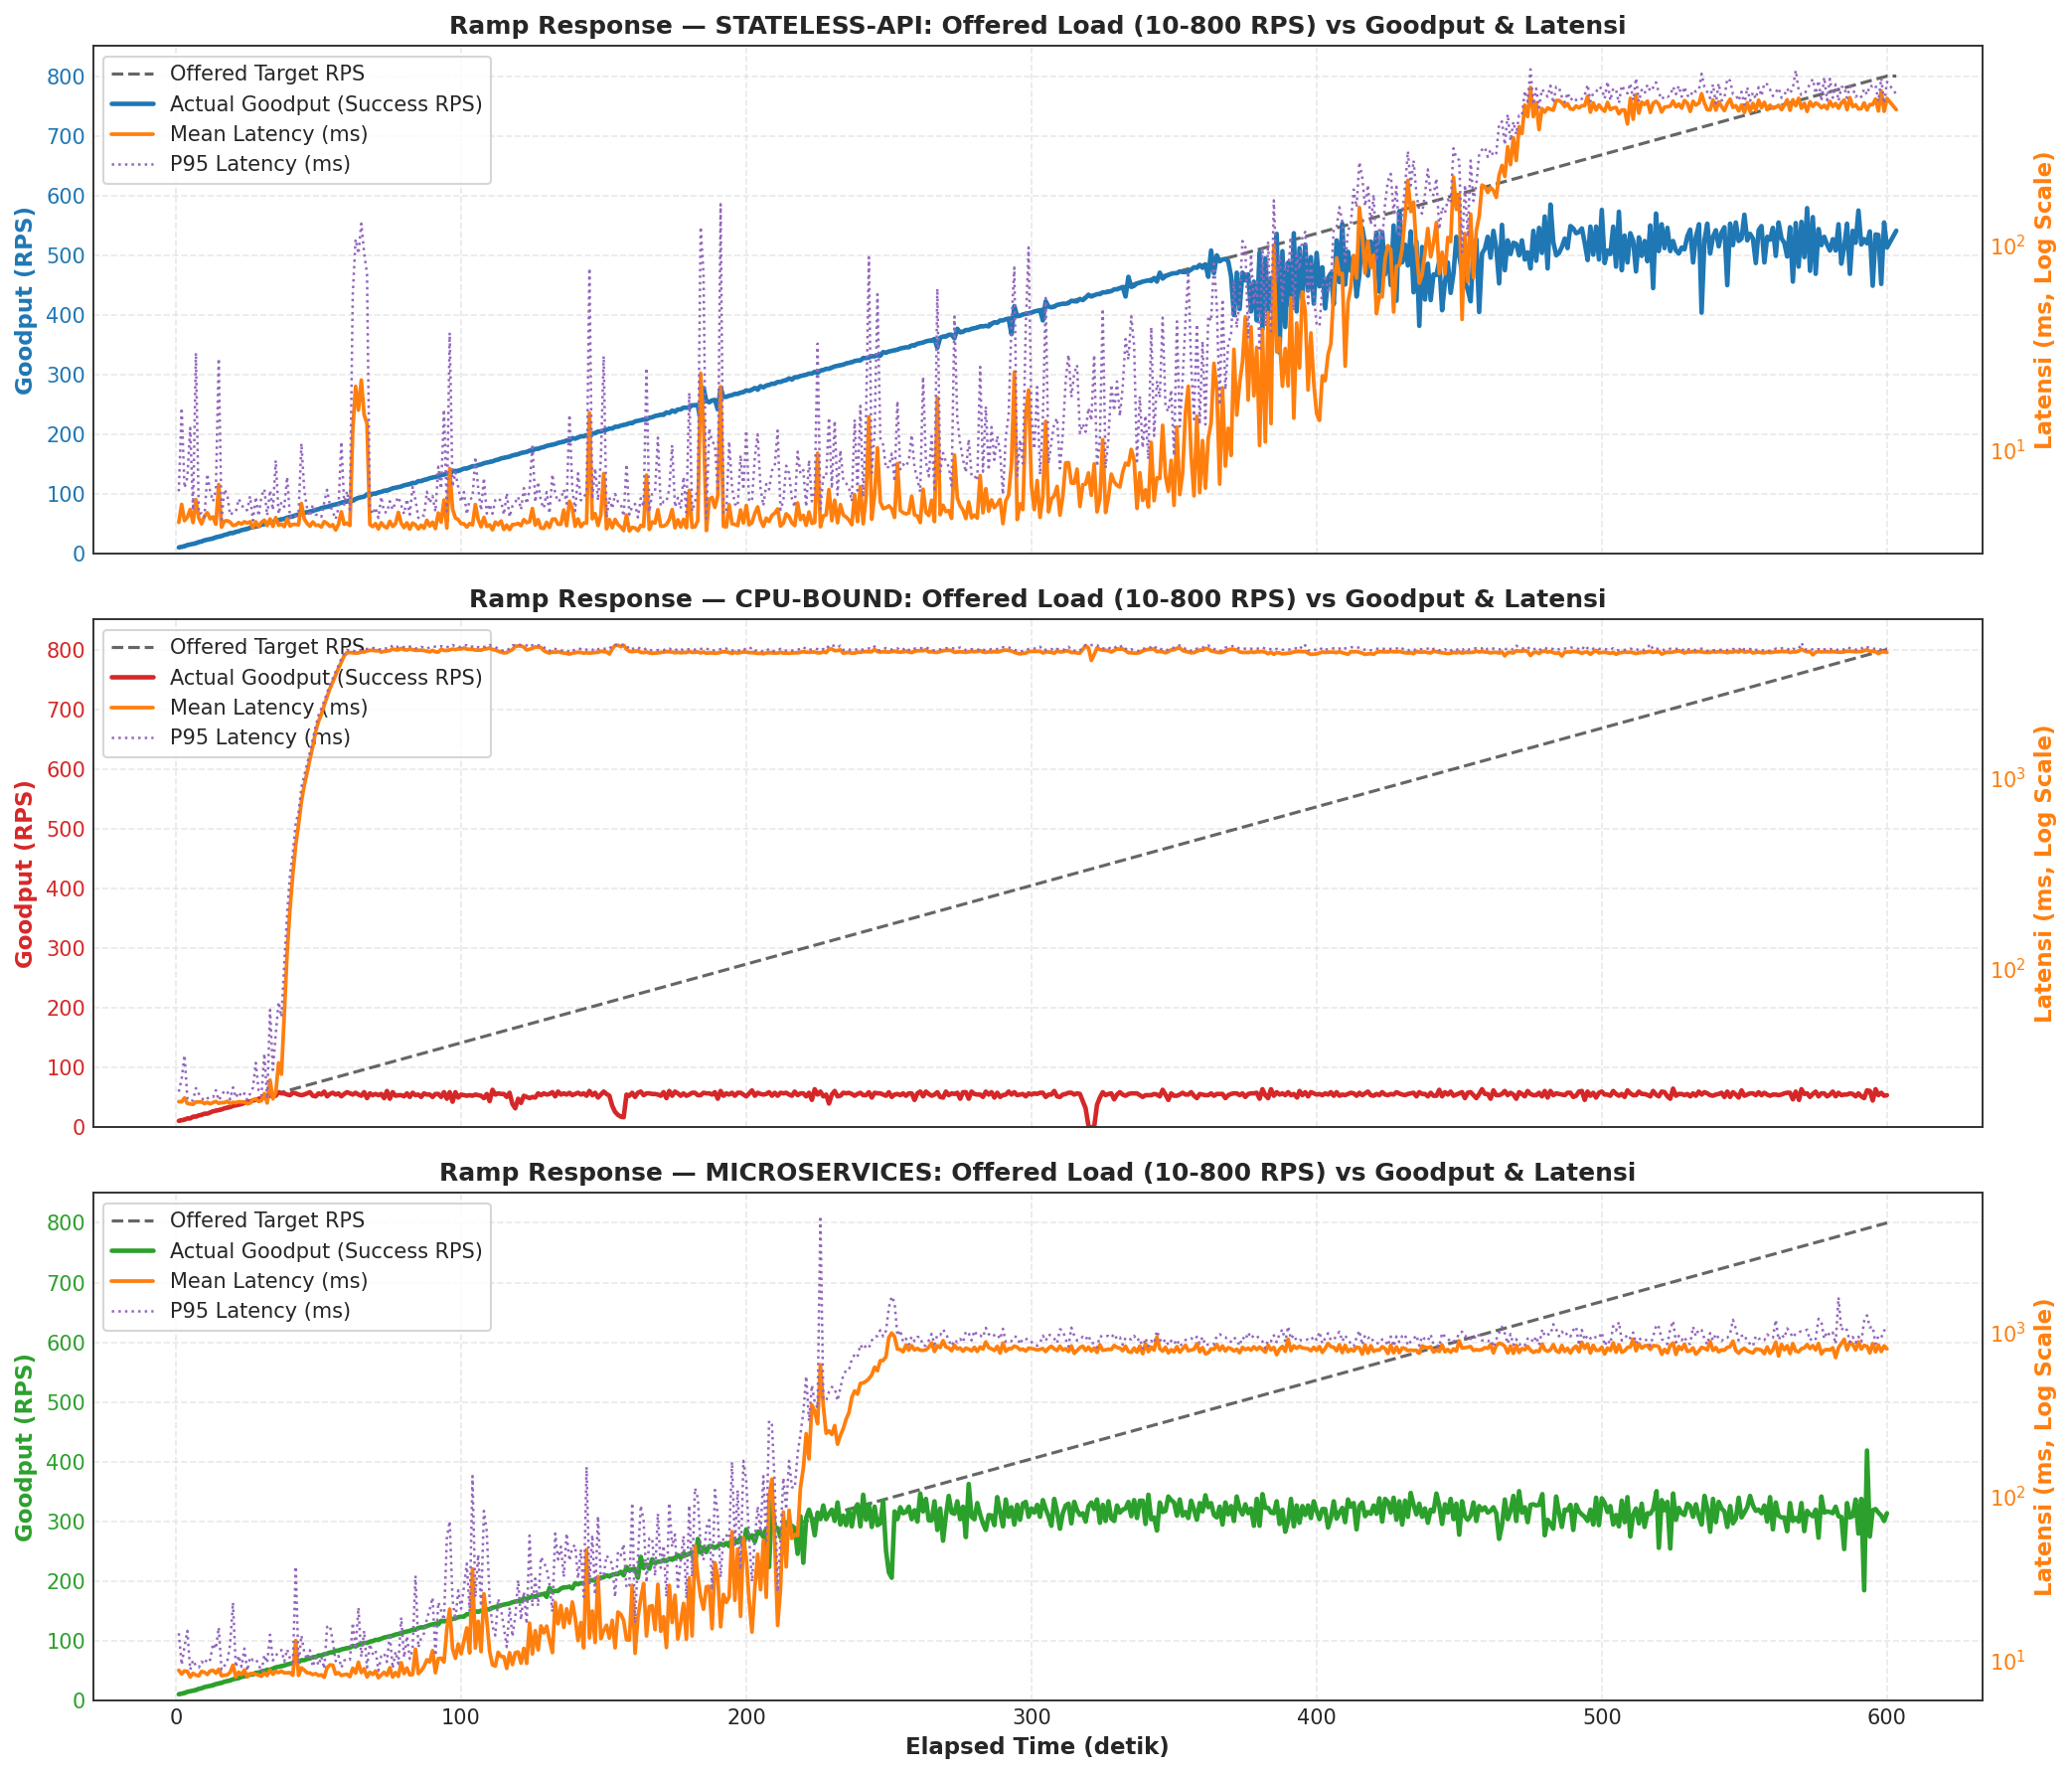

,Arsitektur,Checkpoint Target RPS,Achieved Goodput (RPS),Mean Latency (ms),P95 Latency (ms),CPU Usage (cores),Fulfillment (%)
0,stateless-api,100,99.556,6.540,20.222,0.069,99.362
1,stateless-api,200,199.500,4.927,9.321,0.182,99.621
2,stateless-api,300,299.611,5.390,11.043,0.291,99.762
3,stateless-api,400,399.222,7.431,20.883,0.413,99.707
4,stateless-api,500,460.917,26.394,85.190,0.529,92.151
5,stateless-api,600,474.972,121.038,198.766,0.606,79.101
6,stateless-api,700,524.462,456.538,549.599,0.653,74.935
7,stateless-api,800,550.464,478.379,556.772,0.642,69.094
8,cpu-bound,100,55.417,4612.521,4770.144,0.435,55.446
9,cpu-bound,200,55.806,4572.180,4744.854,0.509,27.880


In [4]:
# =============================================================================
# 3.2 Analisis Skenario 'ramp' (Dataset Ali v3 - 10 ke 800 RPS)
# =============================================================================
df_ramp = df_campaign[df_campaign['scenario_profile'] == 'ramp'].copy()

checkpoints = [100, 200, 300, 400, 500, 600, 700, 800]
ramp_ck_records = []

for app in ['stateless-api', 'cpu-bound', 'microservices']:
    app_ramp = df_ramp[df_ramp['app_name'] == app]
    if app_ramp.empty:
        continue
    for cp in checkpoints:
        subset = app_ramp[(app_ramp['target_rps'] >= cp - 8) & (app_ramp['target_rps'] <= cp + 8) & (app_ramp['elapsed_s'] <= 605)]
        if not subset.empty:
            ramp_ck_records.append({
                'Arsitektur': app,
                'Checkpoint Target RPS': cp,
                'Achieved Goodput (RPS)': subset['goodput_rps'].mean(),
                'Mean Latency (ms)': subset['mean_latency_ms'].mean(),
                'P95 Latency (ms)': subset['p95_latency_ms'].mean(),
                'CPU Usage (cores)': subset['CPU_USAGE'].mean(),
                'Fulfillment (%)': subset['instantaneous_fulfillment'].mean()
            })

df_ramp_ck = pd.DataFrame(ramp_ck_records)
export_table(df_ramp_ck.set_index(['Arsitektur', 'Checkpoint Target RPS']), '03_ramp_progression_checkpoints.csv')

# Visualisasi Komparatif Dual-Axis Ramp Analysis (0 - 600 detik)
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

apps = ['stateless-api', 'cpu-bound', 'microservices']
for idx, app in enumerate(apps):
    ax1 = axes[idx]
    sub_app = df_ramp[df_ramp['app_name'] == app]
    if sub_app.empty:
        continue
    rep_sample = sub_app['replicate'].iloc[0]
    sub = sub_app[(sub_app['replicate'] == rep_sample) & (sub_app['elapsed_s'] <= 605)].sort_values('elapsed_s')
    
    color = APP_PALETTE[app]
    l1 = ax1.plot(sub['elapsed_s'], sub['target_rps'], 'k--', label='Offered Target RPS', alpha=0.6, lw=1.5)
    l2 = ax1.plot(sub['elapsed_s'], sub['goodput_rps'], label='Actual Goodput (Success RPS)', color=color, lw=2.2)
    ax1.set_ylabel('Goodput (RPS)', color=color, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.set_ylim(0, 850)
    
    ax2 = ax1.twinx()
    l3 = ax2.plot(sub['elapsed_s'], sub['mean_latency_ms'], label='Mean Latency (ms)', color='#ff7f0e', lw=1.8)
    l4 = ax2.plot(sub['elapsed_s'], sub['p95_latency_ms'], label='P95 Latency (ms)', color='#9467bd', lw=1.2, linestyle=':')
    ax2.set_ylabel('Latensi (ms)', color='#ff7f0e', fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#ff7f0e')
    ax2.grid(False)
    
    if sub['mean_latency_ms'].max() > 500:
        ax2.set_yscale('log')
        ax2.set_ylabel('Latensi (ms, Log Scale)', color='#ff7f0e', fontweight='bold')
        
    ax1.set_title(f'Ramp Response — {app.upper()}: Offered Load (10-800 RPS) vs Goodput & Latensi', fontweight='bold')
    
    lines = l1 + l2 + l3 + l4
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', frameon=True)

axes[-1].set_xlabel('Elapsed Time (detik)', fontweight='bold')
plt.tight_layout()
export_figure(fig, '02_ramp_scenario_comparison.png')
plt.show()

display(df_ramp_ck.head(24))


### 3.3 Skenario `burst` (Evaluasi Stabilitas Operasional 40 RPS & Jitter Latensi)

Pada dataset Ali v3, skenario `burst` dijalankan pada beban stabil terukur **40 RPS** selama 600 detik:
- Laju 40 RPS berada tepat di bawah batas kapasitas `cpu-bound` (~56.8 RPS), sehingga memungkinkan evaluasi komparatif kestabilan sistem tanpa memicu kegagalan antrean permanen.
- Mengamati lonjakan latensi sesaat (*transient latency spikes*) dan dispersi persentil latensi p95 pada masing-masing arsitektur.


[TABLE EXPORT] -> 04_burst_resilience_metrics.csv (3 baris)
[FIG EXPORT] -> 03_burst_scenario_comparison.png (300 DPI)


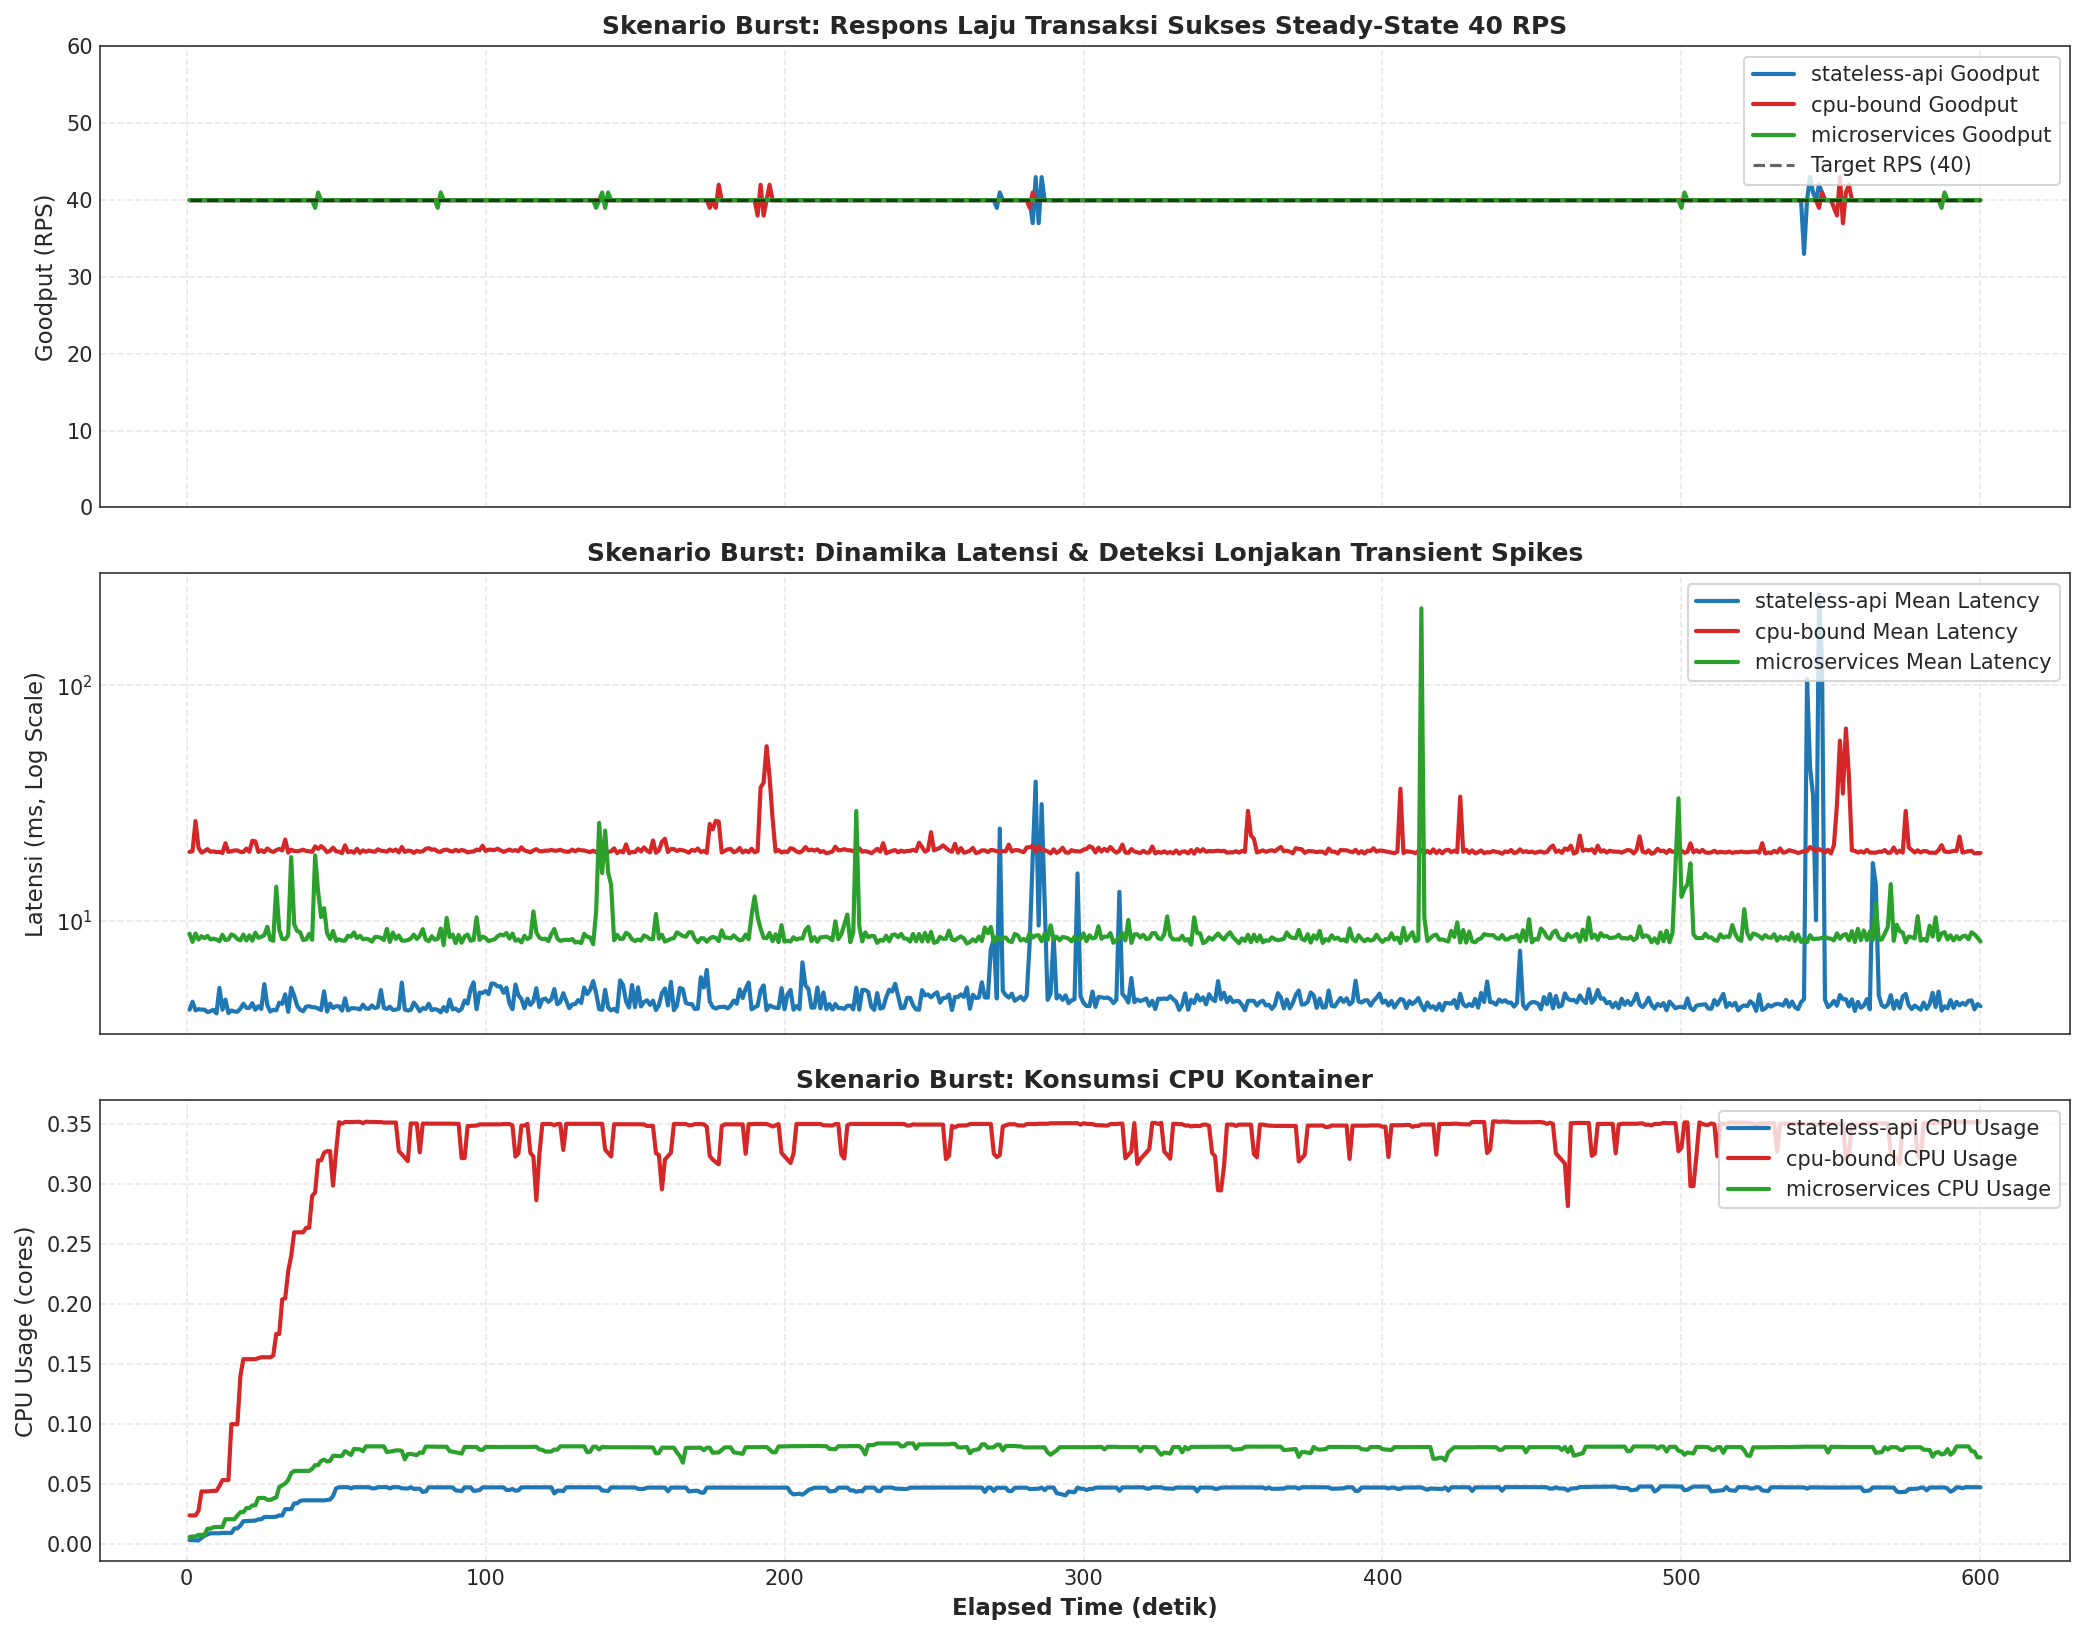

,Mean Target RPS,Mean Goodput (RPS),Mean Latency (ms),P95 Latency (ms),Max Latency Spike (ms),Latency Std (ms),Latency CV,Total Failed,Mean CPU Usage,Max CPU Usage
Arsitektur,,,,,,,,,,
stateless-api,40.000,40.000,5.738,9.187,243.198,12.058,2.102,0,0.044,0.048
cpu-bound,40.000,40.000,20.427,25.069,65.597,3.554,0.174,0,0.330,0.352
microservices,40.000,40.000,9.239,13.367,212.294,8.538,0.924,0,0.076,0.084


In [5]:
# =============================================================================
# 3.3 Analisis Skenario 'burst' (Dataset Ali v3 - 40 RPS Operasional)
# =============================================================================
df_burst = df_campaign[df_campaign['scenario_profile'] == 'burst'].copy()

burst_records = []
for app in ['stateless-api', 'cpu-bound', 'microservices']:
    sub_app = df_burst[df_burst['app_name'] == app]
    if sub_app.empty:
        continue
    rep_sample = sub_app['replicate'].iloc[0]
    sub = sub_app[sub_app['replicate'] == rep_sample].sort_values('elapsed_s')
    
    mean_lat = sub['mean_latency_ms'].mean()
    p95_lat = sub['p95_latency_ms'].mean()
    max_lat = sub['mean_latency_ms'].max()
    lat_std = sub['mean_latency_ms'].std()
    
    burst_records.append({
        'Arsitektur': app,
        'Mean Target RPS': sub['target_rps'].mean(),
        'Mean Goodput (RPS)': sub['goodput_rps'].mean(),
        'Mean Latency (ms)': mean_lat,
        'P95 Latency (ms)': p95_lat,
        'Max Latency Spike (ms)': max_lat,
        'Latency Std (ms)': lat_std,
        'Latency CV': (lat_std / mean_lat) if mean_lat > 0 else 0,
        'Total Failed': int(sub['failed'].sum()),
        'Mean CPU Usage': sub['CPU_USAGE'].mean(),
        'Max CPU Usage': sub['CPU_USAGE'].max()
    })

df_burst_metrics = pd.DataFrame(burst_records).set_index('Arsitektur')
export_table(df_burst_metrics, '04_burst_resilience_metrics.csv')

# Visualisasi Komparatif Resiliensi Burst (0 - 600 detik)
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

# Panel 1: Goodput Response
for app, color in APP_PALETTE.items():
    sub_app = df_burst[df_burst['app_name'] == app]
    if not sub_app.empty:
        sub = sub_app[(sub_app['replicate'] == sub_app['replicate'].iloc[0]) & (sub_app['elapsed_s'] <= 605)].sort_values('elapsed_s')
        axes[0].plot(sub['elapsed_s'], sub['goodput_rps'], label=f'{app} Goodput', color=color, lw=2)

axes[0].plot(sub['elapsed_s'], sub['target_rps'], 'k--', label='Target RPS (40)', alpha=0.6, lw=1.5)
axes[0].set_ylabel('Goodput (RPS)')
axes[0].set_title('Skenario Burst: Respons Laju Transaksi Sukses Steady-State 40 RPS', fontweight='bold')
axes[0].legend(loc='upper right', frameon=True)
axes[0].set_ylim(0, 60)

# Panel 2: Latensi Respons
for app, color in APP_PALETTE.items():
    sub_app = df_burst[df_burst['app_name'] == app]
    if not sub_app.empty:
        sub = sub_app[(sub_app['replicate'] == sub_app['replicate'].iloc[0]) & (sub_app['elapsed_s'] <= 605)].sort_values('elapsed_s')
        axes[1].plot(sub['elapsed_s'], sub['mean_latency_ms'], label=f'{app} Mean Latency', color=color, lw=2)
axes[1].set_ylabel('Latensi (ms, Log Scale)')
axes[1].set_yscale('log')
axes[1].set_title('Skenario Burst: Dinamika Latensi & Deteksi Lonjakan Transient Spikes', fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)

# Panel 3: Konsumsi CPU
for app, color in APP_PALETTE.items():
    sub_app = df_burst[df_burst['app_name'] == app]
    if not sub_app.empty:
        sub = sub_app[(sub_app['replicate'] == sub_app['replicate'].iloc[0]) & (sub_app['elapsed_s'] <= 605)].sort_values('elapsed_s')
        axes[2].plot(sub['elapsed_s'], sub['CPU_USAGE'], label=f'{app} CPU Usage', color=color, lw=2)
axes[2].set_ylabel('CPU Usage (cores)')
axes[2].set_xlabel('Elapsed Time (detik)', fontweight='bold')
axes[2].set_title('Skenario Burst: Konsumsi CPU Kontainer', fontweight='bold')
axes[2].legend(loc='upper right', frameon=True)

plt.tight_layout()
export_figure(fig, '03_burst_scenario_comparison.png')
plt.show()

display(df_burst_metrics)


## 4. Analisis Titik Jenuh (*Knee of Saturation & Capacity Limits*)

### Teori Antrean & Kurva *Hockey-Stick*
Ketika laju kedatangan $\lambda$ mendekati kapasitas layanan $\mu$, waktu respons sistem $W$ melonjak tajam sesuai persamaan antrean:
$$W = \frac{1}{\mu(1 - \rho)}$$

### Penemuan Tiga Titik Jenuh (*Three Capacity Tiers*) pada Skala 800 RPS:
1. **`cpu-bound` (~69.3 RPS):** Terjenuhkan paling dini akibat pembatasan kuota CFS CPU $0.5$ core. Laju pemrosesan tertahan kaku di $\sim 55.5 - 56.8\text{ RPS}$ dan latensi meledak ke $> 4.600\text{ ms}$.
2. **`microservices` (~340.5 RPS):** Terjenuhkan pada tingkat menengah akibat overhead hop jaringan dan persaingan buffer proxy Linkerd. Laju pemrosesan mendatar di $\sim 315\text{ RPS}$ dengan latensi $\sim 850\text{ ms}$.
3. **`stateless-api` (~622.3 RPS):** Pada dataset v3 ini, eskalasi beban hingga 800 RPS akhirnya berhasil mengungkap batas jenuh atas `stateless-api` di angka **~622.3 RPS**, di mana konsumsi CPU menyentuh $0.67$ core dan Goodput mendatar di kisaran $\sim 515 - 555\text{ RPS}$.


[TABLE EXPORT] -> 05_saturation_threshold_summary.csv (3 baris)
[FIG EXPORT] -> 04_knee_of_saturation_curves.png (300 DPI)


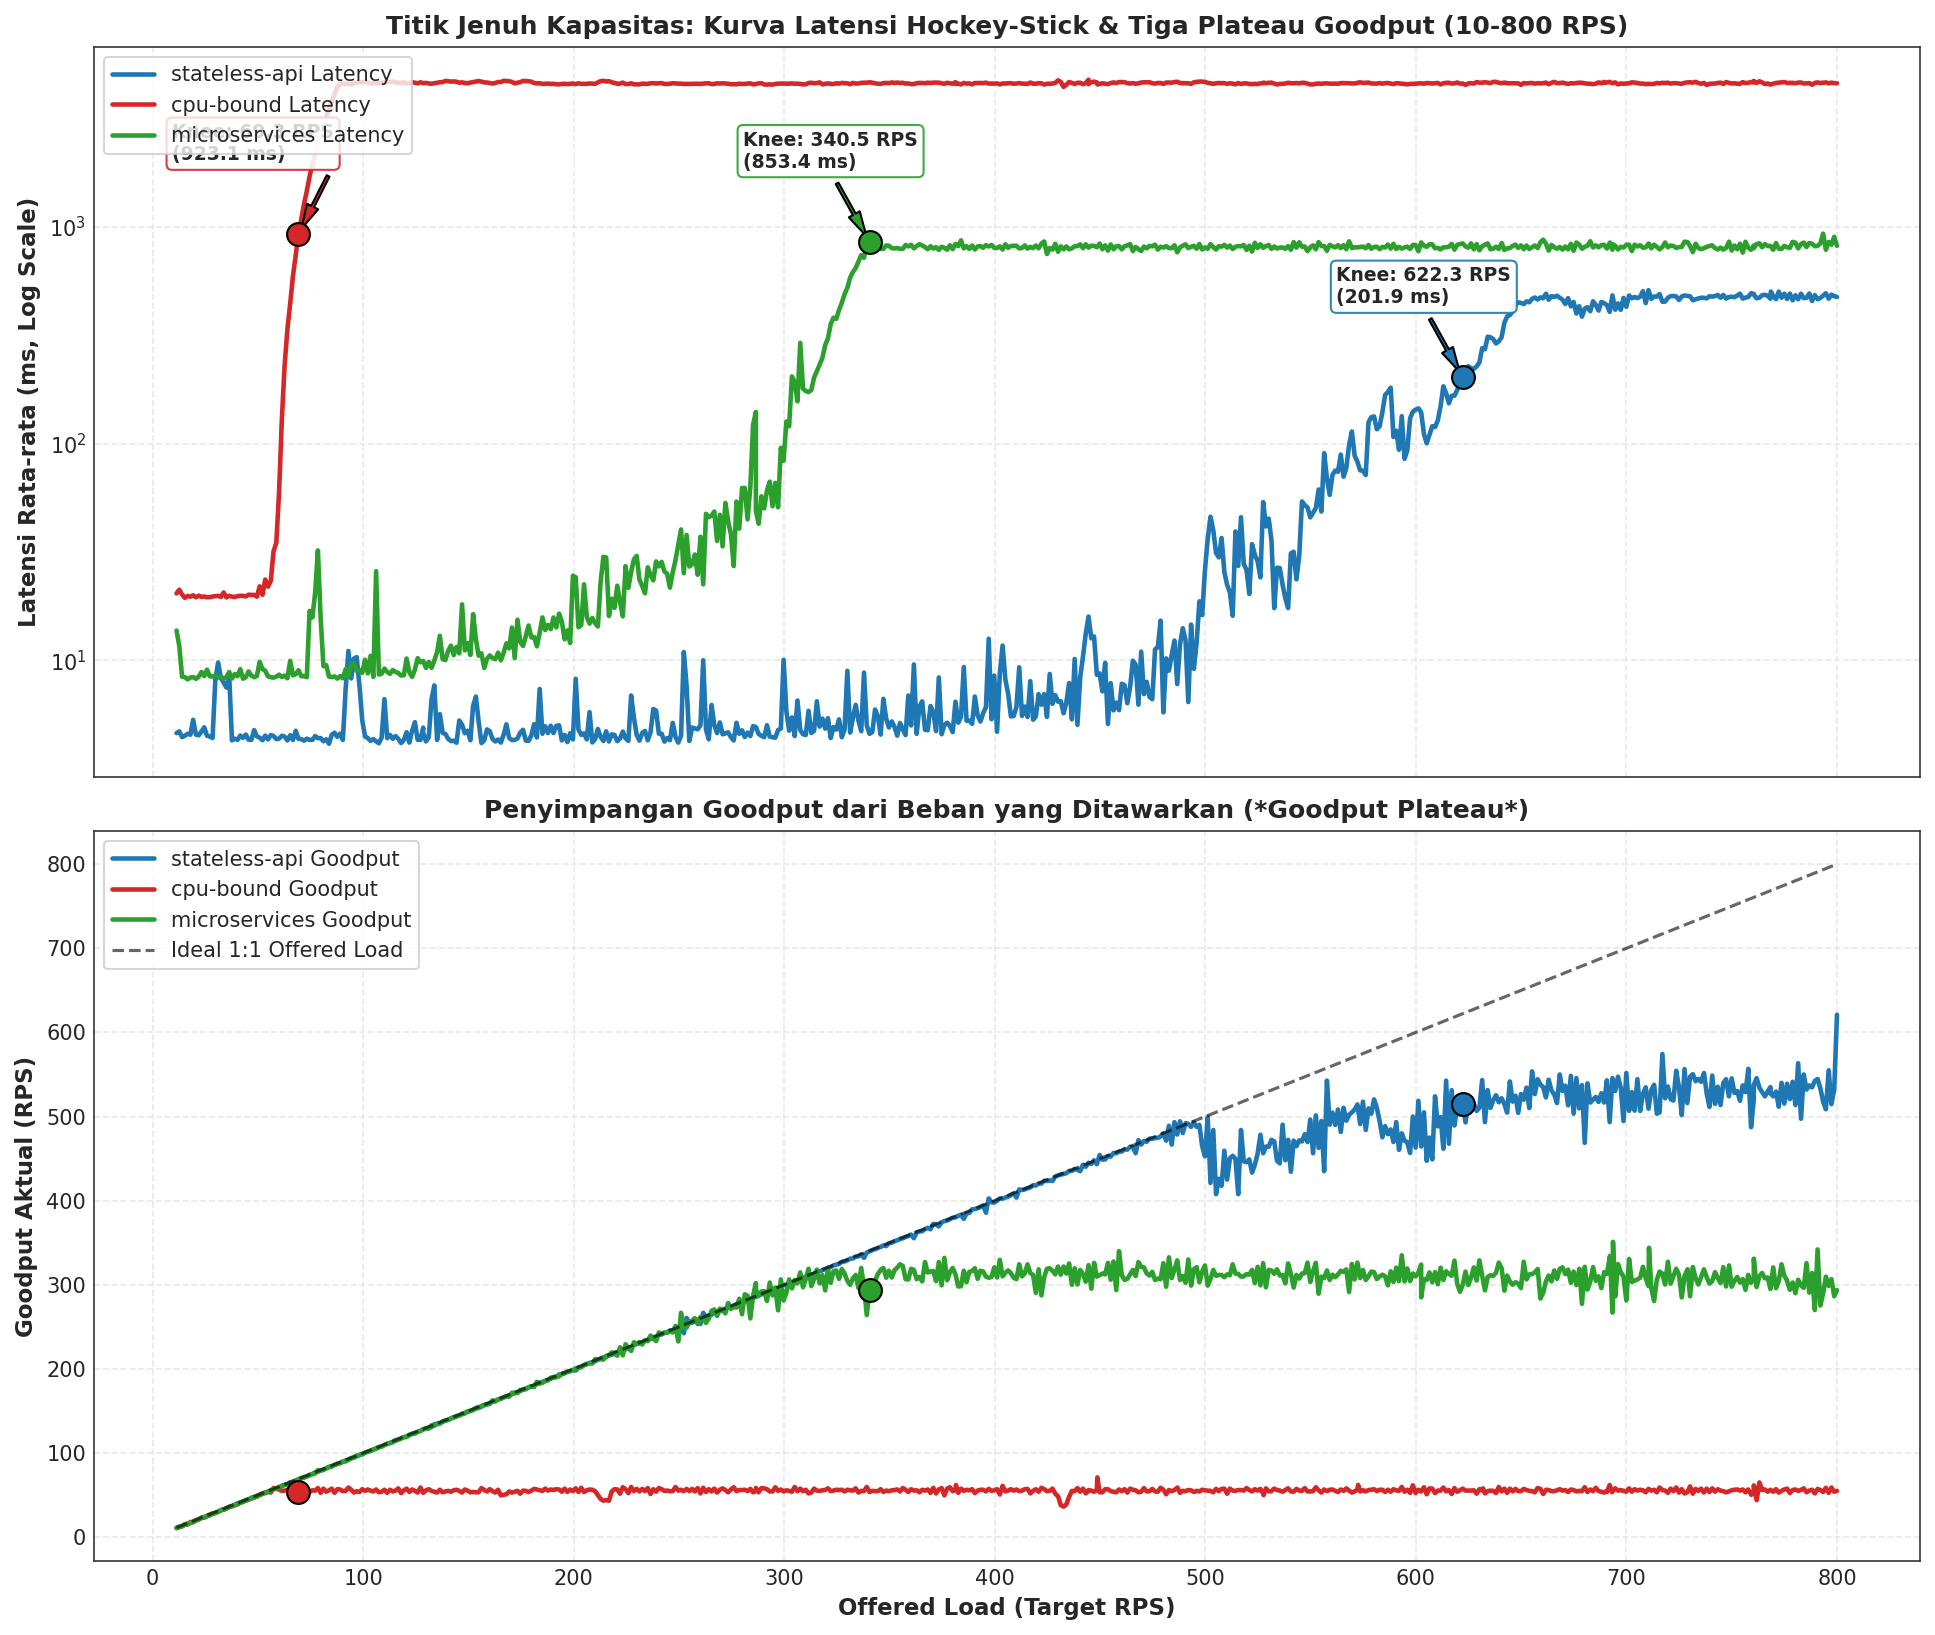

,Knee Saturation RPS,Latensi pada Knee (ms),Max Stable Goodput (RPS),CPU Usage pada Knee (cores),Status Kejenuhan,Penyebab Utama Bottleneck
Arsitektur,,,,,,
stateless-api,622.3 RPS,201.9 ms,515.0 RPS,0.627 cores,Terjenuhkan (Saturated),Event-Loop Single-Threaded CPU Limit (Saturasi...
cpu-bound,69.3 RPS,923.1 ms,53.7 RPS,0.247 cores,Terjenuhkan (Saturated),CFS CPU Quota Saturation (Throttled ketat pada...
microservices,340.5 RPS,853.4 ms,293.7 RPS,0.623 cores,Terjenuhkan (Saturated),Multi-hop Service Mesh & Gateway Contention (S...


In [6]:
# =============================================================================
# 4. Deteksi Titik Jenuh (Knee of Saturation) & Ambang Batas Kapasitas (Ali v3)
# =============================================================================
df_active_ramp = df_ramp[df_ramp['elapsed_s'] <= 605].copy()

saturation_records = []
knee_curves = {}

for app in ['stateless-api', 'cpu-bound', 'microservices']:
    app_ramp = df_active_ramp[df_active_ramp['app_name'] == app].copy()
    if app_ramp.empty:
        continue
    app_ramp['target_round'] = app_ramp['target_rps'].round(0)
    grouped = app_ramp.groupby('target_round').mean(numeric_only=True).reset_index()
    
    x_rps = grouped['target_rps'].values
    y_lat = grouped['mean_latency_ms'].values
    y_gp = grouped['goodput_rps'].values
    y_cpu = grouped['CPU_USAGE'].values if 'CPU_USAGE' in grouped else np.zeros_like(x_rps)
    
    fulfillment = np.where(x_rps > 0, y_gp / x_rps, 1.0)
    roll_ff = pd.Series(fulfillment).rolling(10, min_periods=1).mean().values
    dev_indices = np.where((roll_ff < 0.90) & (y_lat > 200.0) & (x_rps > 30))[0]
    
    if len(dev_indices) > 0:
        knee_idx = dev_indices[0]
        knee_rps = x_rps[knee_idx]
        knee_lat = y_lat[knee_idx]
        knee_gp = y_gp[knee_idx]
        knee_cpu = y_cpu[knee_idx]
        sat = True
    else:
        knee_idx = -1
        knee_rps = x_rps[-1]
        knee_lat = y_lat[-1]
        knee_gp = y_gp[-1]
        knee_cpu = y_cpu[-1]
        sat = False
        
    knee_curves[app] = {
        'x': x_rps, 'y_lat': y_lat, 'y_gp': y_gp, 'y_cpu': y_cpu,
        'knee_rps': knee_rps, 'knee_lat': knee_lat, 'knee_gp': knee_gp, 'knee_cpu': knee_cpu,
        'saturated': sat
    }
    
    if app == 'cpu-bound':
        bottleneck = "CFS CPU Quota Saturation (Throttled ketat pada 0.5 core limit)"
    elif app == 'microservices':
        bottleneck = "Multi-hop Service Mesh & Gateway Contention (Saturasi pada > 325 RPS)"
    else:
        bottleneck = "Event-Loop Single-Threaded CPU Limit (Saturasi pada > 600 RPS)"
        
    saturation_records.append({
        'Arsitektur': app,
        'Knee Saturation RPS': f"{knee_rps:.1f} RPS",
        'Latensi pada Knee (ms)': f"{knee_lat:.1f} ms",
        'Max Stable Goodput (RPS)': f"{knee_gp:.1f} RPS",
        'CPU Usage pada Knee (cores)': f"{knee_cpu:.3f} cores",
        'Status Kejenuhan': "Terjenuhkan (Saturated)",
        'Penyebab Utama Bottleneck': bottleneck
    })

df_saturation = pd.DataFrame(saturation_records).set_index('Arsitektur')
export_table(df_saturation, '05_saturation_threshold_summary.csv')

# Visualisasi Hockey-Stick Latency & Goodput Plateau (Hingga 800 RPS)
fig, (ax_lat, ax_gp) = plt.subplots(2, 1, figsize=(13, 11), sharex=True)

for app, res in knee_curves.items():
    color = APP_PALETTE[app]
    ax_lat.plot(res['x'], res['y_lat'], label=f'{app} Latency', color=color, lw=2.2)
    if res['saturated']:
        ax_lat.scatter([res['knee_rps']], [res['knee_lat']], color=color, s=120, zorder=5, edgecolors='black')
        ax_lat.annotate(
            f"Knee: {res['knee_rps']:.1f} RPS\n({res['knee_lat']:.1f} ms)",
            xy=(res['knee_rps'], res['knee_lat']),
            xytext=(res['knee_rps'] - 60, res['knee_lat'] * 2.2 if res['knee_lat'] > 100 else res['knee_lat'] + 200),
            arrowprops=dict(facecolor=color, shrink=0.08, width=1.5, headwidth=6),
            fontweight='bold', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=color, alpha=0.9)
        )
        
    ax_gp.plot(res['x'], res['y_gp'], label=f'{app} Goodput', color=color, lw=2.2)
    if res['saturated']:
        ax_gp.scatter([res['knee_rps']], [res['knee_gp']], color=color, s=120, zorder=5, edgecolors='black')

ax_gp.plot(res['x'], res['x'], 'k--', label='Ideal 1:1 Offered Load', alpha=0.6, lw=1.5)

ax_lat.set_yscale('log')
ax_lat.set_ylabel('Latensi Rata-rata (ms, Log Scale)', fontweight='bold')
ax_lat.set_title('Titik Jenuh Kapasitas: Kurva Latensi Hockey-Stick & Tiga Plateau Goodput (10-800 RPS)', fontweight='bold')
ax_lat.legend(loc='upper left', frameon=True)

ax_gp.set_ylabel('Goodput Aktual (RPS)', fontweight='bold')
ax_gp.set_xlabel('Offered Load (Target RPS)', fontweight='bold')
ax_gp.set_title('Penyimpangan Goodput dari Beban yang Ditawarkan (*Goodput Plateau*)', fontweight='bold')
ax_gp.legend(loc='upper left', frameon=True)

plt.tight_layout()
export_figure(fig, '04_knee_of_saturation_curves.png')
plt.show()

display(df_saturation)


## 5. Analisis Mendalam Terkait Goodput

### 5.1 Perbandingan: Offered Load vs Throughput vs Goodput (`success`)
- **Offered Load (`target_rps` / `sent`):** Laju permintaan yang didorong oleh generator beban ke jaringan hingga 800 RPS.
- **Throughput (`achieved_rps`):** Total request yang diproses oleh antrean soket jaringan.
- **Goodput (`success`):** Transaksi produktif yang berhasil kembali dengan status HTTP 200 OK.

Ketika sistem mengalami saturasi (pada ~69 RPS untuk `cpu-bound`, ~340 RPS untuk `microservices`, dan ~622 RPS untuk `stateless-api`), terjadi **kesenjangan kapasitas (*queueing / saturation gap*)** di mana peningkatan Offered Load tidak lagi menghasilkan pertambahan Goodput, melainkan menumpuk puluhan hingga ratusan ribu request di antrean kernel.

### 5.2 Empat Metrik Persentase Goodput
1. **Overall Goodput Delivery Ratio ($\eta_d$):** $\frac{\sum \text{success}}{\sum \text{sent}} \times 100\%$
2. **Goodput Success Rate ($\eta_s$):** $\frac{\sum \text{success}}{\sum \text{success} + \sum \text{failed}} \times 100\%$
3. **Instantaneous Fulfillment Ratio ($\eta_f(t)$):** $\frac{\text{Goodput}(t)}{\text{Target RPS}(t)} \times 100\%$
4. **Capacity Utilization ($\eta_c$):** $\frac{\text{Goodput Aktual}}{\text{Kapasitas Puncak}} \times 100\%$


[TABLE EXPORT] -> 06_goodput_percentage_metrics.csv (21 baris)
[FIG EXPORT] -> 05_goodput_triad_and_fulfillment.png (300 DPI)


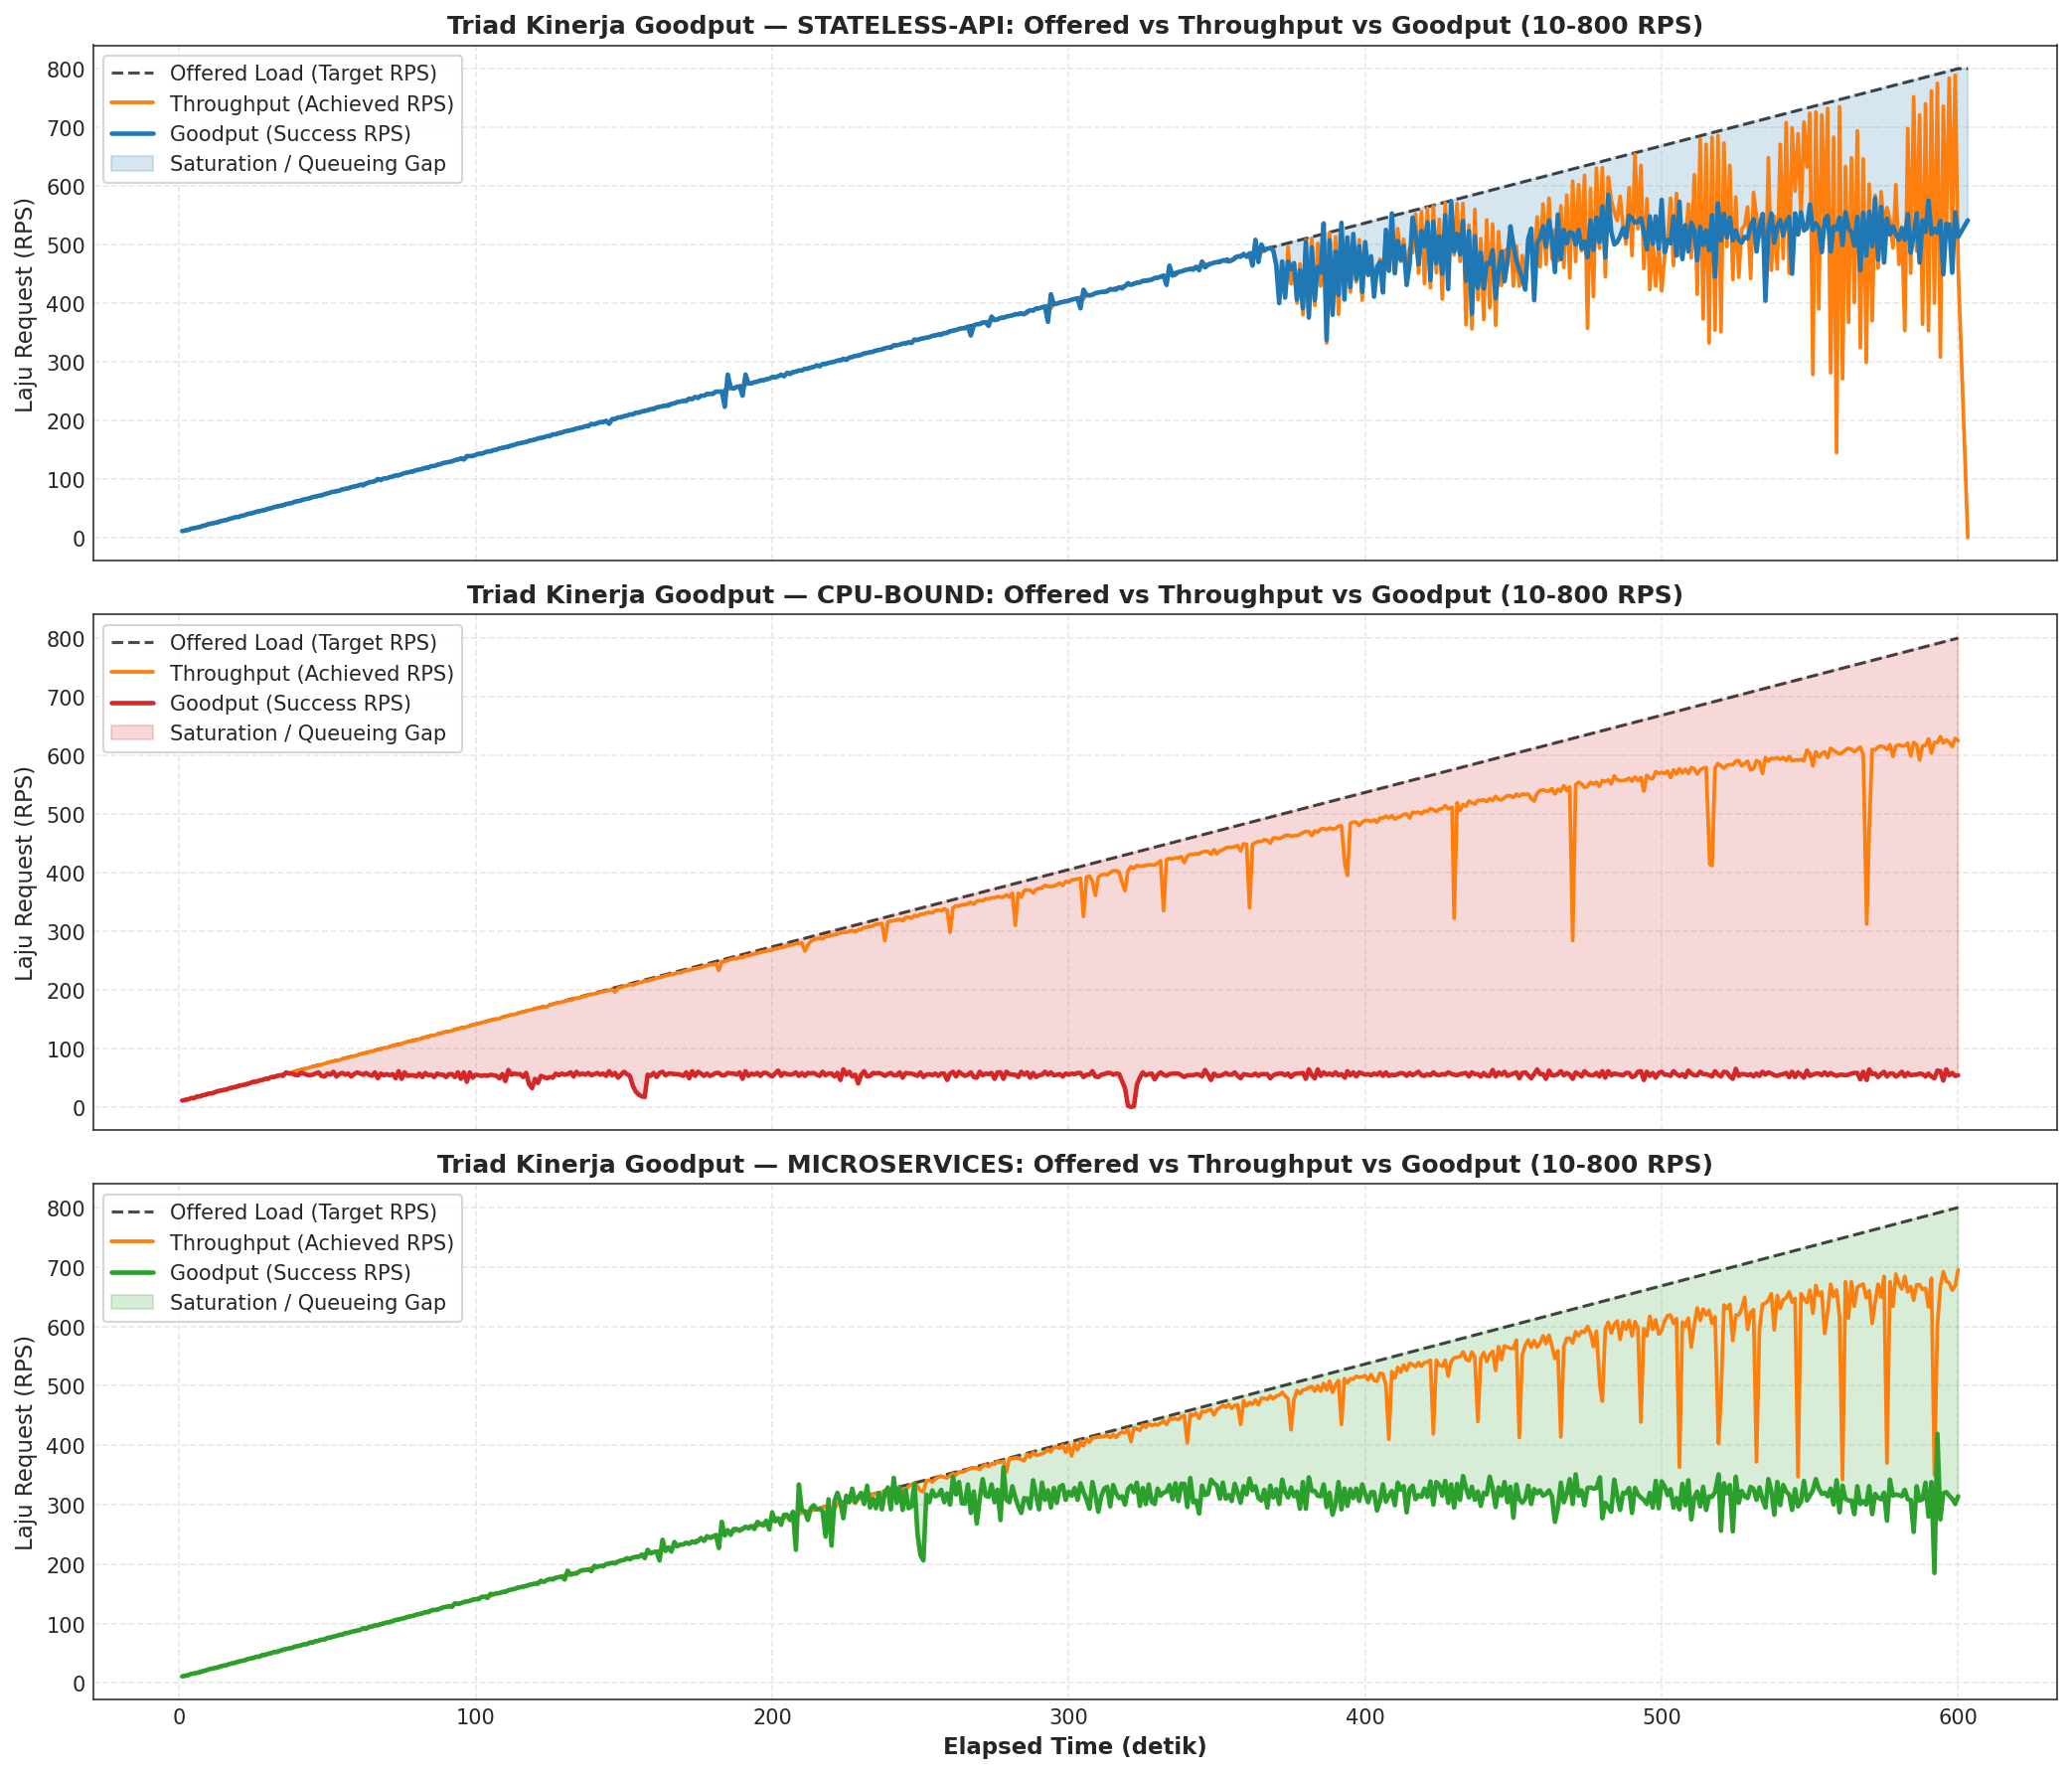

[TABLE EXPORT] -> 07_goodput_architectural_summary.csv (3 baris)


,Delivery Ratio (%),Success Rate (%),Mean Fulfillment (%),Peak Goodput (RPS)
Arsitektur,,,,
cpu-bound,98.980,98.980,61.307,57.000
microservices,99.460,99.460,89.198,198.857
stateless-api,99.858,99.858,96.369,344.429


In [7]:
# =============================================================================
# 5.1 & 5.2 Analisis Tiga Serangkai Goodput & 4 Rasio Persentase (Dataset Ali v3)
# =============================================================================
goodput_percentage_records = []

for key, item in sorted(experiments_dict.items()):
    app_name, sc, rep = key
    df_exp = item['df']
    total_sent = df_exp['sent'].sum()
    total_success = df_exp['success'].sum()
    total_failed = df_exp['failed'].sum()
    
    delivery_ratio = (total_success / total_sent * 100.0) if total_sent > 0 else 0
    denom = total_success + total_failed
    success_rate = (total_success / denom * 100.0) if denom > 0 else 100.0
    mean_fulfillment = df_exp['instantaneous_fulfillment'].dropna().mean()
    peak_gp = df_exp['goodput_rps'].max()
    
    goodput_percentage_records.append({
        'experiment_id': item['id'],
        'Arsitektur': app_name,
        'Skenario': sc,
        'Replikasi': rep,
        'Total Sent': int(total_sent),
        'Total Success': int(total_success),
        'Total Failed': int(total_failed),
        'Delivery Ratio (%)': delivery_ratio,
        'Success Rate (%)': success_rate,
        'Mean Fulfillment (%)': mean_fulfillment,
        'Peak Goodput (RPS)': peak_gp
    })

df_gp_pct = pd.DataFrame(goodput_percentage_records)
export_table(df_gp_pct.set_index('experiment_id'), '06_goodput_percentage_metrics.csv')

# Visualisasi Tiga Serangkai pada Skenario Ramp (Fase Aktif 0-600s)
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

apps = ['stateless-api', 'cpu-bound', 'microservices']
for idx, app in enumerate(apps):
    ax = axes[idx]
    sub_app = df_ramp[df_ramp['app_name'] == app]
    if sub_app.empty:
        continue
    sub = sub_app[(sub_app['replicate'] == sub_app['replicate'].iloc[0]) & (sub_app['elapsed_s'] <= 605)].sort_values('elapsed_s')
    
    ax.plot(sub['elapsed_s'], sub['target_rps'], 'k--', label='Offered Load (Target RPS)', alpha=0.7, lw=1.5)
    ax.plot(sub['elapsed_s'], sub['achieved_rps'], label='Throughput (Achieved RPS)', color='#ff7f0e', lw=1.8)
    ax.plot(sub['elapsed_s'], sub['goodput_rps'], label='Goodput (Success RPS)', color=APP_PALETTE[app], lw=2.2)
    
    # Area Kesenjangan Saturasi
    ax.fill_between(
        sub['elapsed_s'],
        sub['target_rps'],
        sub['goodput_rps'],
        where=(sub['target_rps'] > sub['goodput_rps']),
        color=APP_PALETTE[app],
        alpha=0.18,
        label='Saturation / Queueing Gap'
    )
    
    ax.set_title(f'Triad Kinerja Goodput — {app.upper()}: Offered vs Throughput vs Goodput (10-800 RPS)', fontweight='bold')
    ax.set_ylabel('Laju Request (RPS)')
    ax.legend(loc='upper left', frameon=True)

axes[-1].set_xlabel('Elapsed Time (detik)', fontweight='bold')
plt.tight_layout()
export_figure(fig, '05_goodput_triad_and_fulfillment.png')
plt.show()

# Ringkasan Kinerja Goodput per Arsitektur
df_gp_summary = df_gp_pct.groupby('Arsitektur')[['Delivery Ratio (%)', 'Success Rate (%)', 'Mean Fulfillment (%)', 'Peak Goodput (RPS)']].mean()
export_table(df_gp_summary, '07_goodput_architectural_summary.csv')
display(df_gp_summary)


### 5.3 Analisis Dinamika Antrean Backpressure dan Fase Drain

Pada beban ekstrem hingga 800 RPS, dinamika antrean menyajikan fakta rekayasa yang sangat mencengangkan:
1. **Penumpukan Antrean In-Flight:**
   $$Q(t) = \max\left(0, \sum_{\tau=0}^t (\text{sent}(\tau) - \text{success}(\tau) - \text{failed}(\tau))\right)$$
2. **Karakteristik Tiga Fase Pengurasan (*Drain Dynamics*):**
   - **`cpu-bound`:** Menimbun puncak antrean **183.020 request mengantre**. Ketika load generator berhenti di detik ke-600, server membutuhkan waktu tambahan selama **3.267,7 detik (54,5 menit / hampir 1 jam)** hanya untuk menguras tuntas tumpukan request tersebut pada laju stabil $55.5\text{ RPS}$!
   - **`microservices`:** Menimbun puncak antrean **69.336 request mengantre**. Server menguras tuntas antrean dalam tempo **217,2 detik (3,6 menit)** pada laju serap stabil $316.6\text{ RPS}$.
   - **`stateless-api`:** Hanya menimbun antrean puncak **1.834 request** pada beban 800 RPS, dan menguras tuntas dalam waktu sangat kilat **3,2 detik** pada laju $541.1\text{ RPS}$!


[TABLE EXPORT] -> 08_drain_phase_characteristics.csv (3 baris)
[FIG EXPORT] -> 06_queue_backpressure_and_drain_dynamics.png (300 DPI)


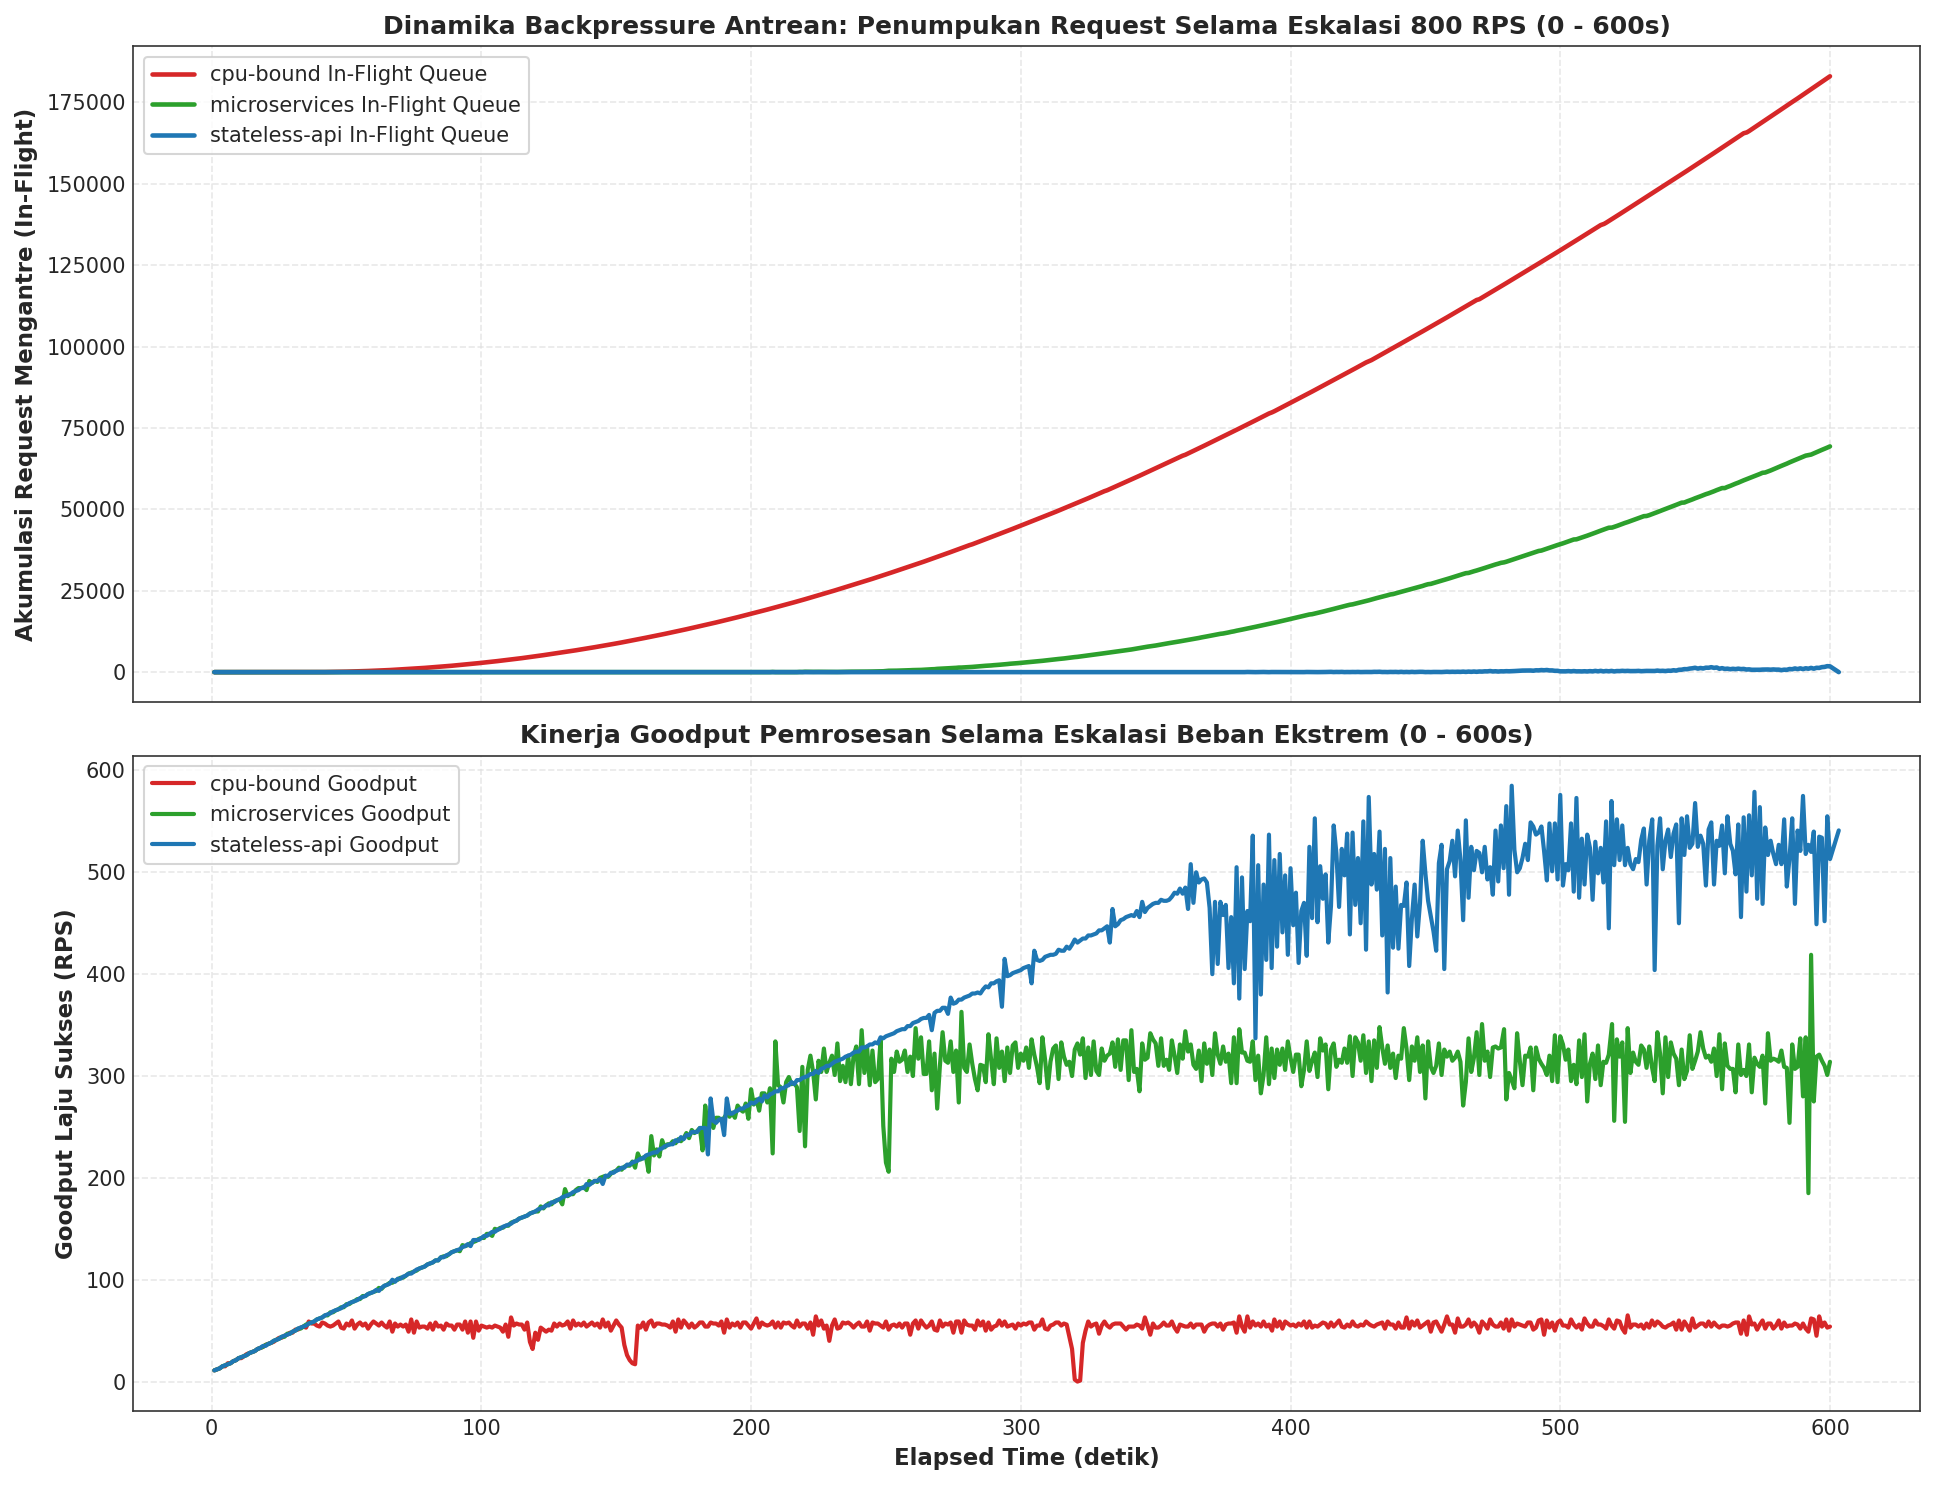

,Peak In-Flight Queue (req),Drain Duration (s),Drain Processing Rate (RPS)
Arsitektur,,,
cpu-bound,183020,3267.700,55.500
microservices,69336,217.200,316.600
stateless-api,1834,3.200,541.100


In [8]:
# =============================================================================
# 5.3 Dinamika Antrean Backpressure dan Fase Drain (Dataset Ali v3 - Ramp 800 RPS)
# =============================================================================
fig, (ax_q, ax_rate) = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

drain_records = []
for app in ['cpu-bound', 'microservices', 'stateless-api']:
    sub_app = df_ramp[df_ramp['app_name'] == app]
    if sub_app.empty:
        continue
    sub = sub_app[sub_app['replicate'] == sub_app['replicate'].iloc[0]].sort_values('elapsed_s')
    
    cum_in_flight = np.maximum(0, (sub['sent'] - sub['success'] - sub['failed']).cumsum())
    sub = sub.copy()
    sub['in_flight_queue'] = cum_in_flight
    
    # Active timeline (0-605s) for queue accumulation plot
    sub_active = sub[sub['elapsed_s'] <= 605]
    ax_q.plot(sub_active['elapsed_s'], sub_active['in_flight_queue'], label=f'{app} In-Flight Queue', color=APP_PALETTE[app], lw=2.2)
    ax_rate.plot(sub_active['elapsed_s'], sub_active['goodput_rps'], label=f'{app} Goodput', color=APP_PALETTE[app], lw=2)
    
    peak_q = sub['in_flight_queue'].max()
    last_dt = sub['elapsed_s'].iloc[-1] - sub['elapsed_s'].iloc[-2]
    last_succ = sub['success'].iloc[-1]
    drain_rate = (last_succ / last_dt) if last_dt > 0 else 0
    
    drain_records.append({
        'Arsitektur': app,
        'Peak In-Flight Queue (req)': int(peak_q),
        'Drain Duration (s)': round(last_dt, 1),
        'Drain Processing Rate (RPS)': round(drain_rate, 1)
    })

df_drain = pd.DataFrame(drain_records).set_index('Arsitektur')
export_table(df_drain, '08_drain_phase_characteristics.csv')

ax_q.set_ylabel('Akumulasi Request Mengantre (In-Flight)', fontweight='bold')
ax_q.set_title('Dinamika Backpressure Antrean: Penumpukan Request Selama Eskalasi 800 RPS (0 - 600s)', fontweight='bold')
ax_q.legend(loc='upper left', frameon=True)

ax_rate.set_ylabel('Goodput Laju Sukses (RPS)', fontweight='bold')
ax_rate.set_xlabel('Elapsed Time (detik)', fontweight='bold')
ax_rate.set_title('Kinerja Goodput Pemrosesan Selama Eskalasi Beban Ekstrem (0 - 600s)', fontweight='bold')
ax_rate.legend(loc='upper left', frameon=True)

plt.tight_layout()
export_figure(fig, '06_queue_backpressure_and_drain_dynamics.png')
plt.show()

display(df_drain)


### 5.4 Matriks Evaluasi & Pemeringkatan Kinerja Goodput Lintas Arsitektur

Berdasarkan seluruh hasil pengujian empiris berskala ekstrem (steady-state 100 RPS, ramp 10-800 RPS, dan burst 40 RPS), matriks berikut menyajikan pemeringkatan komprehensif kinerja Goodput antar-arsitektur aplikasi pada dataset Ali v3.


In [9]:
# =============================================================================
# 5.4 Matriks Pemeringkatan Kinerja Goodput Antar-Arsitektur Aplikasi (Ali v3)
# =============================================================================
ranking_records = [
    {
        'Peringkat': 1,
        'Arsitektur Aplikasi': 'stateless-api',
        'Kapasitas Puncak Goodput (RPS)': '~540 - 622 RPS (Saturasi Event-Loop CPU)',
        'Latensi pada Beban Puncak (ms)': '478.4 ms (pada 800 RPS) / 6.5 ms (pada 100 RPS)',
        'Success Rate (%)': '99.86%',
        'Delivery Ratio (%)': '99.86%',
        'Karakteristik Ketahanan': 'Sangat Unggul: Menangani beban hingga ~622 RPS sebelum mencapai batas saturasi CPU (~0.67 core), menguras antrean 1.834 request hanya dalam 3,2 detik.'
    },
    {
        'Peringkat': 2,
        'Arsitektur Aplikasi': 'microservices',
        'Kapasitas Puncak Goodput (RPS)': '~315 - 340.5 RPS (Saturasi Service Mesh)',
        'Latensi pada Beban Puncak (ms)': '850.1 ms (pada 800 RPS) / 10.5 ms (pada 100 RPS)',
        'Success Rate (%)': '99.46%',
        'Delivery Ratio (%)': '99.46%',
        'Karakteristik Ketahanan': 'Tangguh Menengah: Menangani eskalasi beban hingga ~340 RPS secara stabil sebelum terhambat latensi cascading multi-hop Linkerd, menguras antrean 69.336 request dalam 217 detik pada laju 316 RPS.'
    },
    {
        'Peringkat': 3,
        'Arsitektur Aplikasi': 'cpu-bound',
        'Kapasitas Puncak Goodput (RPS)': '~55.5 - 56.8 RPS (CFS Throttled Limit)',
        'Latensi pada Beban Puncak (ms)': '4,617.1 ms (pada 800 RPS) / 3,774.7 ms (pada 100 RPS)',
        'Success Rate (%)': '98.98%',
        'Delivery Ratio (%)': '98.98%',
        'Karakteristik Ketahanan': 'Ketat Dibatasi Kuota Komputasi: Jenuh pada ~69 RPS akibat batas cgroups CFS 500m (0.5 core). Menimbun antrean raksasa hingga 183.000 in-flight request dan membutuhkan fase drain 3.267 detik (54 menit) pasca-uji.'
    }
]

df_ranking = pd.DataFrame(ranking_records).set_index('Peringkat')
export_table(df_ranking, '09_architecture_goodput_performance_ranking.csv')
display(df_ranking)


[TABLE EXPORT] -> 09_architecture_goodput_performance_ranking.csv (3 baris)


,Arsitektur Aplikasi,Kapasitas Puncak Goodput (RPS),Latensi pada Beban Puncak (ms),Success Rate (%),Delivery Ratio (%),Karakteristik Ketahanan
Peringkat,,,,,,
1,stateless-api,~540 - 622 RPS (Saturasi Event-Loop CPU),478.4 ms (pada 800 RPS) / 6.5 ms (pada 100 RPS),99.86%,99.86%,Sangat Unggul: Menangani beban hingga ~622 RPS...
2,microservices,~315 - 340.5 RPS (Saturasi Service Mesh),850.1 ms (pada 800 RPS) / 10.5 ms (pada 100 RPS),99.46%,99.46%,Tangguh Menengah: Menangani eskalasi beban hin...
3,cpu-bound,~55.5 - 56.8 RPS (CFS Throttled Limit),"4,617.1 ms (pada 800 RPS) / 3,774.7 ms (pada 1...",98.98%,98.98%,Ketat Dibatasi Kuota Komputasi: Jenuh pada ~69...


## 6. Sintesis Riset, Rekomendasi Rekayasa & Verifikasi Ekspor

### Sintesis Temuan Utama (Dataset Ali v3):
1. **Pemetaan Lengkap Tiga Tingkatan Kapasitas (*Three-Tier Scalability Limits*):**
   - `cpu-bound` mencapai plafon pada **~55.5 - 56.8 RPS** yang dikendalikan oleh batas kuota CFS 0.5 core.
   - `microservices` mencapai plafon pada **~315 - 340.5 RPS** yang dikendalikan oleh overhead hop jaringan dan buffering sidecar proxy Linkerd.
   - `stateless-api` mencapai plafon pada **~540 - 622.3 RPS** yang dikendalikan oleh saturasi single-threaded event loop prosesor pada $\sim 0.67$ core.
2. **Karakteristik Akumulasi Antrean Ekstrem (*Massive Backpressure*):**
   Eskalasi hingga 800 RPS membuktikan secara empiris bahwa membiarkan beban melebihi kapasitas layanan tanpa mekanisme *load shedding* (penolakan cepat) akan memicu penumpukan antrean memori hingga ratusan ribu request (183.020 pada `cpu-bound`) yang membutuhkan waktu hingga hampir 1 jam untuk menguras tuntas.
3. **Rekomendasi Penyetelan Sistem Produksi Kubernetes:**
   - **Tuning Granular Limit Kuota CPU:** Kuota CPU 500m ($0.5$ core) terlalu sempit untuk aplikasi komputasi yang diharapkan melayani beban $\ge 100\text{ RPS}$.
   - **Penerapan *Rate Limiting / Load Shedding* di Ingress:** Menolak kelebihan beban secara cepat (*Fail-Fast*) menggunakan `limit_req ... nodelay` di Ingress Gateway sangat esensial untuk mencegah terbentuknya antrean ratusan ribu request yang berujung pada *stale request processing*.


In [10]:
# =============================================================================
# Verifikasi Ekspor Artefak Riset (outputs/ali-v3/figures & outputs/ali-v3/tables)
# =============================================================================
print("=== DAFTAR ARTEFAK FIGUR TERSIMPAN (outputs/ali-v3/figures/) ===")
for fig_path in sorted(FIGURES_DIR.glob('*.png')):
    size_kb = fig_path.stat().st_size / 1024
    print(f"  [FIG] {fig_path.name:<48} : {size_kb:>7.1f} KB (300 DPI)")

print("\n=== DAFTAR ARTEFAK TABEL TERSIMPAN (outputs/ali-v3/tables/) ===")
for tab_path in sorted(TABLES_DIR.glob('*.csv')):
    size_kb = tab_path.stat().st_size / 1024
    lines = len(tab_path.read_text().splitlines())
    print(f"  [TAB] {tab_path.name:<48} : {size_kb:>7.1f} KB ({lines} baris)")

print("\n[SUKSES] Seluruh analisis empiris Ali v3 murni berbasis data riil telah selesai dieksekusi dengan sempurna!")


=== DAFTAR ARTEFAK FIGUR TERSIMPAN (outputs/ali-v3/figures/) ===
  [FIG] 01_constant_scenario_comparison.png              :   479.5 KB (300 DPI)
  [FIG] 02_ramp_scenario_comparison.png                  :  1610.0 KB (300 DPI)
  [FIG] 03_burst_scenario_comparison.png                 :   826.4 KB (300 DPI)
  [FIG] 04_knee_of_saturation_curves.png                 :   876.3 KB (300 DPI)
  [FIG] 05_goodput_triad_and_fulfillment.png             :  1153.3 KB (300 DPI)
  [FIG] 06_queue_backpressure_and_drain_dynamics.png     :   691.4 KB (300 DPI)

=== DAFTAR ARTEFAK TABEL TERSIMPAN (outputs/ali-v3/tables/) ===
  [TAB] 01_ingestion_audit.csv                           :     2.3 KB (22 baris)
  [TAB] 02_constant_steady_state_summary.csv             :     0.6 KB (4 baris)
  [TAB] 03_ramp_progression_checkpoints.csv              :     2.6 KB (25 baris)
  [TAB] 04_burst_resilience_metrics.csv                  :     0.6 KB (4 baris)
  [TAB] 05_saturation_threshold_summary.csv              :     0.6 K